# The paper's eight main figures, prepared for submission

Everything here is rendered to the journal's artwork rules: **≤ 180 mm wide, 5–7 pt sans-serif
(DejaVu Sans), ≥ 300 dpi**, written as **PDF + PNG**.

Three things differ from `paper_main_figures_v2.ipynb`, which stays the working notebook:

* **No figure titles.** Each figure is preceded by a markdown cell holding its complete legend,
  written to be pasted straight into the manuscript. Panel titles stay on the figures.
* **Re-laid-out, not re-saved.** The working figures are 14.5–17 in wide (368–432 mm), so simply
  scaling them to 180 mm would render their 6.8–13 pt type at 3–5 pt. Every layout here is built at
  the target width.
* **PDF, not EPS.** Measured on this paper's own geometry, PDF is 2.7–5.3× smaller (the six-row map figure:
  3.7 MB vs 10.4 MB), but the deciding reason is that **EPS cannot represent transparency**, and
  season is encoded *as shade* in Figures 6c and 7b. An EPS export would have collapsed four
  seasons into one without erroring.

The analysis is byte-identical to the working notebook: same run tag, same threshold, same
detector, same tables. Only the rendering differs.

## 0 · Setup

In [ ]:
%load_ext autoreload
%autoreload 2

In [3]:
import gc
import json
from dataclasses import replace
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib import gridspec

from cordex2energy_analysis.analysis import compute_sign_agreement
from cordex2energy_analysis.extremes_analysis import (
    attribution_change_by_model,
    compute_c2e_gwl_field,
    compute_country_gwl_field,
    compute_deficit_budget,
    compute_duration_stratified_metrics,
    compute_exceedance_probability,
    compute_evening_peak_attribution,
    DEFICIT_WINDOW_HOURS,
    EVENING_PEAK_HOURS,
    compute_flexibility_attenuation_metrics,
    compute_multi_day_table,
    compute_event_season_metrics,
    mask_structural_zeros,
    resolve_gwl_period_definitions,
)
from cordex2energy_analysis.extremes_events import (
    calculate_climatological_baseline,
    compute_continuous_system_metrics,
)
from cordex2energy_analysis.extremes_thresholds import compute_active_threshold
from cordex2energy_analysis.figure_cache import cached, country_monthly, demand_monthly
from cordex2energy_analysis.plotting_extremes import resolve_model_periods
from cordex2energy_analysis.plotting_paper import MAP_CRS, PaperStyle, load_country_geometry
from cordex2energy_analysis.plotting_si import ZONE_COLORS
from cordex2energy_analysis.plotting_publication import (
    FS,
    europe_change_figure,
    europe_change_table,
    europe_change_summary,
    markdown_table,
    season_label,
    blend,
    align_colorbar_labels,
    GWL_TITLE,
    level_handles,
    panel_scenario_bars,
    QUANTITY_CMAP,
    CBAR_PAD, MM, SEASON_COUNT_BINS_MULTI_DAY, SEASON_COUNT_BINS_SUB_DAILY, WIDTH,
    driver_handles,
    fit_width,
    gwl_handles,
    legend_below,
    mean_state_maps,
    panel_driver_attribution,
    panel_event_frequency,
    panel_hour_of_day,
    panel_letter,
    panel_letters,
    regime_figure,
    zone_tail_duration_figure,
    panel_dumbbell,
    panel_season_contribution,
    panel_storage_stack,
    publication_rc,
    save,
    season_contribution_by_model,
    storage_handles,
    tail_exceedance_figure,
)
from cordex2energy.utils.constants import REFERENCE_PERIOD
from cordex2energy.conversion_energy.tyndp import REALTIME_BALANCING_ZONES


In [4]:
# ── Configuration. The ANALYSIS settings are copied verbatim from paper_main_figures_v2.ipynb.
# Nothing below may drift from that notebook: any difference here must be a difference in the
# RENDERING, never in the numbers.
paths = json.load(open("../paths.json"))
PATH_PROCESSED = Path(paths["path_data_processed"])
PATH_RESIDUAL_LOAD = PATH_PROCESSED / "extremes" / "residual_load"
PATH_DEMAND = PATH_PROCESSED / "energy" / "europe" / "demand"
FIGS = Path(paths.get("path_figs", "../figs")) / "paper_publication"
FIGS.mkdir(parents=True, exist_ok=True)

CLIMATE_SCENARIO = "rcp85"
RUN_TAG = "DE_2050_c2edem_LOW_2050_freecool_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"
# HIGH at the SAME target year as the paper's LOW run, so the comparison isolates the ambition
# of the build-out rather than confounding it with the year it is built for.
RUN_TAG_HIGH_2050 = "DE_2050_c2edem_HIGH_2050_freecool_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"

#: Figures 7 AND 7 are each drawn one panel row tall; this is that row, measured on Figure 6 and Supplementary Fig. S31.
# Measured, not guessed: `fit_width` scales each figure to land on 180 mm, so this is the
# pre-scaling height that puts Figure 7's panel at 40.7 mm and Figure 8's at 41.0, between
# Figure 6's top row (41.6 mm) and Supplementary Fig. S31's (40.0 mm). The two figures need the same constant
# despite carrying two and three panels respectively, because what this fixes is the ASPECT and
# the per-figure text margins that do not scale with it happen to net out. `save` prints every
# figure's panel height, which is how any drift from this gets noticed.
PANEL_ROW_MM = 43.2

THRESHOLD_PERCENTILE = 95.0
EVENT_DETECTION = "spa"
WARMING_LEVELS = [1.5, 2.0, 3.0]
DURATION_BINS = {"sub_daily": (0, 24), "multi_day": (24, float("inf"))}
DURATION_LABELS = {"sub_daily": "sub-daily\n(\u2264 24 h)", "multi_day": "multi-day\n(> 24 h)"}
ROBUSTNESS_FRACTION = 2 / 3
# "iqr" (P25-P75) is the convention for every shaded BAND and error bar in the paper. Box plots
# are unaffected: a box already means the IQR and its whiskers the classical 1.5xIQR rule, which
# `panel_event_frequency` sets directly rather than deriving from this. The previous value,
# "tukey", made the bands the Tukey whiskers while `panel_hour_of_day` drew P25-P75 from
# `spread_percentiles` regardless -- so Figure 6c's band and 3d's error bars beside it were two
# different conventions.
SPREAD = "iqr"
MAIN_SEASONS = ("DJF", "JJA")          # the two seasons the main text argues over

ZONE_ORDER = ["Iberian_Peninsula", "South_East", "Central_Western",
              "Central_Eastern", "Nordic", "British_Isles"]
ZONE_LABELS = {"Iberian_Peninsula": "Iberia", "South_East": "South-East",
               "Central_Western": "Central-West", "Central_Eastern": "Central-East",
               "Nordic": "Nordic", "British_Isles": "British Isles"}
print("run tag:", RUN_TAG)
print("figures ->", FIGS)

run tag: DE_2050_c2edem_LOW_2050_freecool_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600
figures -> /home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/figs/paper_publication


In [5]:
# ── Zonal residual load + components for the 9 chains ───────────────────────────────────
residual_load_zonal, components_zonal = [], []
for folder in sorted(PATH_RESIDUAL_LOAD.glob("*")):
    run_dir = folder / RUN_TAG
    if not folder.is_dir() or folder.name == "cerra" or not run_dir.exists():
        continue
    model = "_".join(folder.name.split("_")[:-1])
    residual_load_zonal.append(
        xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(model=[model]))
    components_zonal.append(
        xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(model=[model]))
residual_load_zonal = xr.concat(residual_load_zonal, dim="model", join="outer")
components_zonal = xr.concat(components_zonal, dim="model", join="outer")

models = list(residual_load_zonal["model"].values)
zones = [z for z in ZONE_ORDER if z in [str(x) for x in residual_load_zonal["zone"].values]]
print(f"Loaded {len(models)} chains \u00d7 {len(zones)} zones")

Loaded 9 chains × 6 zones


In [6]:
# ── Seasons, palettes, GWL windows, PaperStyle ──────────────────────────────────────────
SEASON_MAP = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
              6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]
SEASON_MONTHS = {s: [m for m, name in SEASON_MAP.items() if name == s] for s in SEASON_ORDER}

# "Reservoir Hydro" renamed "Hydro Reservoir" so the two hydro entries read as a pair in the
# legend. The key is display text only; attribution_change_by_model maps it back to the column
# name by replacing spaces with underscores, so the rename must be mirrored there (see below).
DRIVER_PALETTE = {"Demand": "#D95F02", "PV": "#E6AB02", "Wind Onshore": "#7570B3",
                  "Wind Offshore": "#1B7C3D", "Hydro RoR": "#3182BD",
                  "Reservoir Hydro": "#08519C", "Battery": "#8B5A2B"}
DRIVER_DISPLAY = {"Reservoir Hydro": "Hydro Reservoir"}
DURATION_PALETTE = {"sub_daily": "#3182bd", "multi_day": "#e6550d"}
GWL_COLORS = ["#4A90E2", "#F5A623", "#D0021B"]
ROBUSTNESS_THRESHOLD = int(np.ceil(len(models) * ROBUSTNESS_FRACTION))

period_defs, _, _ = resolve_gwl_period_definitions(
    warming_levels=WARMING_LEVELS, models=models, chain_meta_path="../models.json",
    gwl_yaml_path=PATH_PROCESSED / "cmip5_warming_levels_all_ens_1861_1900.yml",
    climate_scenario=CLIMATE_SCENARIO)
period_names = list(period_defs.keys())
REFERENCE, WARMEST = period_names[0], period_names[-1]

STYLE = PaperStyle(
    zones=zones, zone_labels=ZONE_LABELS, period_names=period_names,
    gwl_colors=dict(zip(period_names, GWL_COLORS)), driver_palette=DRIVER_PALETTE,
    duration_palette=DURATION_PALETTE, season_order=SEASON_ORDER, n_models=len(models),
    robustness_threshold=ROBUSTNESS_THRESHOLD, spread=SPREAD)
print(f"periods {period_names} | robustness {ROBUSTNESS_THRESHOLD}/{len(models)}"
      f" | spread {STYLE.spread_label}")

periods ['+1.5°C', '+2.0°C', '+3.0°C'] | robustness 6/9 | spread IQR (P25–P75)


In [7]:
# ── The deficit threshold: CERRA p95 of the POSITIVE residual load, per zone ────────────
cerra = PATH_RESIDUAL_LOAD / "cerra" / RUN_TAG
cerra_rl = xr.open_dataset(cerra / "residual_load_zonal.nc")
cerra_components = xr.open_dataset(cerra / "components_zonal.nc")
shared_time = np.intersect1d(cerra_rl.time.values, cerra_components.time.values)
cerra_rl, cerra_components = cerra_rl.sel(time=shared_time), cerra_components.sel(time=shared_time)
cerra_metrics = compute_continuous_system_metrics(
    cerra_rl, cerra_components, calculate_climatological_baseline(cerra_components))
zone_threshold = compute_active_threshold(
    cerra_metrics["residual_load"].where(cerra_metrics["residual_load"] > 0),
    "PERCENTILE", percentile=THRESHOLD_PERCENTILE)

residual_load_by_model, components_by_model, threshold_by_model = {}, {}, {}
system_metrics_by_model = {}
for model in models:
    rl = residual_load_zonal.sel(model=model).drop_vars("model", errors="ignore").dropna("time", how="all")
    comp = components_zonal.sel(model=model).drop_vars("model", errors="ignore").dropna("time", how="all")
    shared = np.intersect1d(rl.time.values, comp.time.values)
    residual_load_by_model[model] = rl.sel(time=shared)
    components_by_model[model] = comp.sel(time=shared)
    threshold_by_model[model] = zone_threshold
    system_metrics_by_model[model] = compute_continuous_system_metrics(
        residual_load_by_model[model], components_by_model[model],
        calculate_climatological_baseline(
            components_by_model[model].sel(time=slice(*REFERENCE_PERIOD))))

print(f"CERRA p{THRESHOLD_PERCENTILE:.0f} threshold (GWh / 3 h):")
for zone in zones:
    print(f"  {ZONE_LABELS[zone]:<14} {float(zone_threshold.sel(zone=zone)):>7.1f}")

CERRA p95 threshold (GWh / 3 h):
  Iberia            76.9
  South-East       137.2
  Central-West     434.3
  Central-East     192.1
  Nordic            57.0
  British Isles    145.2


## 1 · Analysis tables

In [9]:
# ── Every table the five figures are drawn from ─────────────────────────────────────────
# Cached on disk (cordex2energy_analysis.figure_cache). The key holds the run's input files, every
# setting the detector reads and a hash of the analysis code, so changing any of them recomputes;
# C2E_FIGCACHE=refresh forces it.
started = time.perf_counter()


def _tables():
    events_annual = compute_duration_stratified_metrics(
        residual_load_by_model, system_metrics_by_model, threshold_by_model, period_defs, models, zones,
        method=EVENT_DETECTION, duration_bins=DURATION_BINS)

    # ONE detection pass, each event assigned whole to the season carrying most of its timesteps.
    # Detecting separately inside each season is a different run of the detector: its counts do not sum
    # to the annual ones, and splitting an event at a season boundary can leave both halves under 24 h,
    # demoting a genuine multi-day event to two sub-daily ones.
    events_by_season = compute_event_season_metrics(
        residual_load_by_model, threshold_by_model, period_defs, models, zones,
        SEASON_MAP, SEASON_ORDER, method=EVENT_DETECTION, duration_bins=DURATION_BINS)

    # `return_events` because Figure 7b is a distribution over event DURATION, which the per-cell
    # summary averages away. Same detection pass, no extra cost beyond keeping the rows.
    storage_attenuation, storage_events = compute_flexibility_attenuation_metrics(
        residual_load_by_model, components_by_model, threshold_by_model, period_defs, models, zones,
        duration_bins=DURATION_BINS, method=EVENT_DETECTION, return_events=True)

    deficit_budget, diurnal_profiles = compute_deficit_budget(
        residual_load_by_model, threshold_by_model, period_defs, zones, method=EVENT_DETECTION)

    # `hours=DEFICIT_WINDOW_HOURS`, not the evening peak alone. Sub-daily events run 10-14 h and spill
    # out of the evening into the night: only 44 % of Iberia's event timesteps at +3.0 C fall in
    # 15-21 h against 53 % in 0-6 h. The window is now the pair of bands the diurnal panel shades, so
    # the panel and its decomposition describe the same hours -- which the caption already claimed.
    evening_peak_components = compute_evening_peak_attribution(
        residual_load_by_model, components_by_model, period_defs, zones, SEASON_MAP,
        hours=DEFICIT_WINDOW_HOURS)

    # attribution_seasons defaults to ("DJF", "JJA") and was never overridden, which is why Supplementary Fig. S31c
    # could only decompose two seasons. Panel 4b now shows that only the South-East gains in summer,
    # so the decomposition has to cover the seasons the other zones actually move in.
    multi_day_events, multi_day_by_season = compute_multi_day_table(
        residual_load_by_model, components_by_model, threshold_by_model, period_defs, zones,
        SEASON_MAP, SEASON_ORDER, method=EVENT_DETECTION, attribution_seasons=SEASON_ORDER)
    return (events_annual, events_by_season, storage_attenuation, storage_events, deficit_budget,
            diurnal_profiles, evening_peak_components, multi_day_events, multi_day_by_season)


(events_annual, events_by_season, storage_attenuation, storage_events, deficit_budget,
 diurnal_profiles, evening_peak_components, multi_day_events, multi_day_by_season) = cached(
    "main_tables", _tables,
    key=dict(run_tag=RUN_TAG, models=models, zones=zones, threshold=zone_threshold,
             periods=period_defs, reference=REFERENCE_PERIOD, method=EVENT_DETECTION,
             durations=DURATION_BINS, seasons=SEASON_MAP, season_order=SEASON_ORDER,
             window=DEFICIT_WINDOW_HOURS),
    files=[PATH_RESIDUAL_LOAD / folder / RUN_TAG / name
           for folder in [f"{m}_{CLIMATE_SCENARIO}" for m in models] + ["cerra"]
           for name in ("residual_load_zonal.nc", "components_zonal.nc")])

# The invariant the change exists to create: exact, not to a tolerance.
_annual = events_annual.set_index(["model", "period", "zone", "duration_class"])["freq_per_year"]
_seasonal = events_by_season.groupby(["model", "period", "zone", "duration_class"])[
    "freq_per_year"].sum()
assert np.allclose(_seasonal.sort_index().values,
                   _annual.sort_index().reindex(_seasonal.sort_index().index).values), \
    "the four seasonal frequencies no longer sum to the annual frequency"
print("seasonal counts sum to the annual count exactly")

assert {"MAM_Demand", "SON_RL"} <= set(multi_day_events.columns), \
    "the attribution table is still two-season; Supplementary Fig. S31c would silently drop MAM and SON"
print(f"tables built [{time.perf_counter() - started:.0f}s]")

[cache] hit   main_tables  (12 MB, 0s)
seasonal counts sum to the annual count exactly
tables built [0s]


In [10]:
# ── Exceedance hours: ONE hour \u00d7 season table serving Figure 5b/4c and Figure 6b ───────
# Detector-free (values above the zone threshold), so it can sit beside the survival curves
# without a consistency caveat.
rows = []
for model in models:
    series = residual_load_by_model[model]["residual_load"]
    for period in period_names:
        window = resolve_model_periods(period_defs, model).get(period)
        if window is None:
            continue
        chunk = series.sel(time=slice(*window))
        times = pd.DatetimeIndex(chunk["time"].values)
        n_years = len(np.unique(times.year))
        for zone in zones:
            over = chunk.sel(zone=zone).values > float(zone_threshold.sel(zone=zone))
            for season in SEASON_ORDER:
                in_season = np.isin(times.month, SEASON_MONTHS[season])
                for hour in np.unique(times.hour):
                    at_hour = times.hour == hour
                    rows.append(dict(model=model, period=period, zone=zone, season=season,
                                     hour=int(hour),
                                     hours_yr=3.0 * int((over & in_season & at_hour).sum())
                                     / n_years))
hour_exceedance = pd.DataFrame(rows)
season_exceedance = (hour_exceedance
                     .groupby(["model", "period", "zone", "season"], as_index=False)["hours_yr"]
                     .sum())

# The southern pair is where the sub-daily surge lives; pool it per chain, THEN take the ensemble
# median, so the median is of a physical quantity and not a median of two medians.
southern_hours = (hour_exceedance[hour_exceedance.zone.isin(["Iberian_Peninsula", "South_East"])]
                  .groupby(["model", "period", "season", "hour"], as_index=False)["hours_yr"].sum())

# freq_per_year \u00d7 avg_duration_h IS extreme-event hours per year (same 3 h step, same detector).
events_by_season = events_by_season.assign(
    hours_yr=events_by_season["freq_per_year"] * events_by_season["avg_duration_h"])
# `events_by_season` IS the burden table Figure 5b draws: one row per (model, period, zone,
# season, duration_class). It is passed whole rather than pre-aggregated, so the panel can take the
# median across chains itself and no zone or class is summed away before it gets there.
print(f"exceedance tables: {len(hour_exceedance):,} rows | "
      f"burden table {events_by_season.shape}")

# The numbers Figure 5b draws, printed so the panel can be checked against the manuscript without
# reading them off the bars. Panel b is EVENT hours: a duration class only exists once an event has
# been detected, so unlike panel a this half of the figure depends on the detector.
_burden = (events_by_season.groupby(["season", "duration_class", "zone", "period"])["hours_yr"]
           .median())
print("\nFigure 2b, extreme-event hours per year (median across chains):")
for _season in MAIN_SEASONS:
    for _class in DURATION_BINS:
        _row = "  ".join(f"{ZONE_LABELS[z]} "
                         + "/".join(
                             f"{np.nan_to_num(_burden.get((_season, _class, z, p), 0.0)):.0f}"
                             for p in period_names)
                         for z in zones)
        print(f"  {_season} {_class:<10} {_row}")

# Panel 3b carries "hours above P95" because it IS the exceedance quantity, not the SPA event hours
# of Figure 5c: `southern_hours` is `hour_exceedance` for two zones, so summing it back over the
# hour of day has to reproduce those zones' rows of the table Figure 5b draws. Exact by
# construction, which is the point — rewiring 3b onto the event budget would trip this and force
# the y-label to be revisited rather than left saying the wrong thing.
_south = ["Iberian_Peninsula", "South_East"]
assert np.allclose(
    southern_hours.groupby(["model", "period", "season"])["hours_yr"].sum().sort_index().values,
    (season_exceedance[season_exceedance.zone.isin(_south)]
     .groupby(["model", "period", "season"])["hours_yr"].sum().sort_index().values)), \
    "panel 3b no longer sums to the exceedance hours of its zones; check its y-label"
print("panel 3b = exceedance hours of Iberia + South-East, resolved by hour of day")


exceedance tables: 5,184 rows | burden table (1296, 9)

Figure 2b, extreme-event hours per year (median across chains):
  DJF sub_daily  Iberia 117/168/196  South-East 123/114/111  Central-West 47/44/44  Central-East 100/94/98  Nordic 24/22/23  British Isles 29/27/33
  DJF multi_day  Iberia 22/36/42  South-East 585/606/478  Central-West 168/148/176  Central-East 400/365/369  Nordic 20/20/18  British Isles 43/49/74
  JJA sub_daily  Iberia 9/19/47  South-East 14/32/90  Central-West 0/0/0  Central-East 0/1/10  Nordic 11/8/7  British Isles 7/6/9
  JJA multi_day  Iberia 0/0/0  South-East 7/13/63  Central-West 0/0/0  Central-East 0/0/0  Nordic 12/11/12  British Isles 8/9/7
panel 3b = exceedance hours of Iberia + South-East, resolved by hour of day


## 2 · Figure 1: the conversion pipeline

The schematic is assembled outside these notebooks; its three inset panels are rendered by
`si_note1_pipeline.ipynb` (section 1) into `figs/si_note1_pipeline/pipeline/`.

> **Figure 1 | The CORDEX2Energy conversion pipeline.** Each EURO-CORDEX chain is
> bias-corrected against CERRA, converted to demand and to solar, wind and hydro generation, and
> aggregated to the six balancing zones, where generation is subtracted from demand to give the
> residual load the paper analyses. Inset panels show what the chain emits at the demand stage:
> annual cooling demand for Spain, nine chains thin and their ensemble median bold, at +1.5 °C,
> +2.0 °C and +3.0 °C of global warming, on one vertical scale. The horizontal axis is the year
> *within* each chain's own 20-year warming-level window, so the three panels are comparable even
> though the windows fall in different decades.


## 3 · Figures 2 and 3: the mean state

Six quantities at three warming levels were one 6 × 3 grid of equal-area maps, 219 mm tall: each
map is limited by its height, so no width made it fit the page. Split by role, supply (Figure 2)
and demand with the residual load it sets (Figure 3), each grid is 3 × 3 at full width, the maps are
a third larger, and the +2.0 °C column stays.

> **Figure 2 | Warming weakens renewable supply slightly and unevenly across Europe.**
> Country-level annual generation at +1.5 °C (left column) and its change (Δ) from +1.5 °C at
> +2.0 °C and +3.0 °C (centre, right), as the median across nine EURO-CORDEX chains under RCP8.5.
> **a**, Solar generation. **b**, Wind generation (onshore and offshore). **c**, Hydro generation
> (run-of-river plus reservoir dispatch). Change columns show the percentage change and run blue to
> red, red being more generation. Colour classes are binned at fixed edges, symmetric about zero, the
> pale central class being no material change. Hatching marks countries where fewer than six of nine
> chains agree on the sign of the change, and is suppressed inside the neutral class. Grey: outside
> the study's country set, no capacity for that technology, or a +1.5 °C level below 0.2 % of the
> row's 90th percentile. ETRS89 Lambert azimuthal equal-area projection (EPSG:3035).

> **Figure 3 | Warming moves demand from heating to cooling and reshapes the residual load.**
> As Figure 2, for demand and the residual load. **a**, Heating demand. **b**, Cooling demand.
> **c**, Residual load (demand minus generation; positive denotes a deficit). Rows **a** and **b**
> show the percentage change; **c** shows the absolute change in TWh yr⁻¹, because the residual load
> is signed and a percentage inverts for countries in surplus. Red is more of the quantity each row
> plots; the residual-load *level* is on its own teal-to-brown scale, teal for surplus and brown for
> deficit. Binning, hatching, grey and projection as in Figure 2.


In [13]:
# ── Country fields for Figures 2 and 3 ───────────────────────────────────────────────────────
# ETRS89-LAEA (EPSG:3035), the EU's equal-area projection: drawn areas are true areas. The earlier
# lon/lat maps were stretched to their panel box and inflated the north.
countries = load_country_geometry(
    PATH_PROCESSED / "maps" / "natural_earth" / "ne_50m_admin_0_countries.geojson", crs=MAP_CRS)

# Each Figure 2/3 map is ~55 mm wide for 52\u00b0 of longitude, so 1\u00b0 \u2248 1.06 mm and a 0.02\u00b0
# displacement is ~0.02 mm \u2014 an order of magnitude below print resolution. Simplifying at that
# tolerance halves the vector file (3.7 -> 2.0 MB) with no visible change. Figures 2 and 3 only; every
# other consumer keeps the full geometry.
countries_print = countries.copy()
countries_print["geometry"] = countries.geometry.simplify(2000.0)   # metres, ~0.02 deg
assert set(countries_print["ISO2"]) == set(countries["ISO2"]), "simplification dropped a country"
assert countries_print.geometry.is_valid.all(), "simplification produced invalid geometry"

# MONTHLY totals, not the 3-hourly and daily series. Every field below slices whole-year GWL
# windows, filters whole months and sums by year, so calendar-month sums are an exact substitute
# (checked to 1e-9) at ~1/250 of the size, and both are cached on disk
# (cordex2energy_analysis.figure_cache): a rerun skips the pass over the raw files entirely.
country_output_by_model = country_monthly(
    {m: PATH_RESIDUAL_LOAD / f"{m}_{CLIMATE_SCENARIO}" / RUN_TAG for m in models},
    ("residual_load.nc", "components.nc"))

started = time.perf_counter()
# Monthly sums of the DAILY-MEAN demand (GW), as built before; countries keyed by name until mapped.
demand_by_month = demand_monthly(PATH_DEMAND, models, CLIMATE_SCENARIO)
from cordex2energy.conversion_energy.tyndp import (build_c2e_name_to_iso2,
                                                   load_tyndp_country_codes)
NAME_TO_ISO2 = build_c2e_name_to_iso2(load_tyndp_country_codes(
    PATH_PROCESSED / "extremes" / "tyndp"
    / "Demand_Scenarios_TYNDP_2024_After_Public_Consultation.xlsb"))
for name, array in demand_by_month.items():
    demand_by_month[name] = array.assign_coords(
        country=[NAME_TO_ISO2.get(str(c), str(c)) for c in array["country"].values])
unmapped = [c for c in map(str, demand_by_month["heating"]["country"].values) if len(c) != 2]
print(f"demand product loaded [{time.perf_counter() - started:.0f}s]"
      f"{'  [WARN] unmapped: ' + str(unmapped) if unmapped else ''}")


def country_field(expression, period):
    return compute_country_gwl_field(country_output_by_model, period_defs, period, expression)


def demand_field(variable, period):
    # scale=24e-3: the monthly totals are sums of daily means in GW, so a period-mean total is
    # GW*24 h = GWh -> TWh.
    return compute_c2e_gwl_field(demand_by_month, period_defs, period, variable, scale=24e-3)


FIG1_QUANTITIES = [
    ("Solar generation", lambda p: country_field(lambda d: d["gen_pv"], p), "plasma", None),
    ("Wind generation",  lambda p: country_field(lambda d: d["gen_wind_on"] + d["gen_wind_off"], p),
     "Greens", None),
    ("Hydro generation", lambda p: mask_structural_zeros(
        country_field(lambda d: d["gen_hydro_ror"] + d["reservoir_dispatch_gwh"], p)),
     QUANTITY_CMAP["Hydro"], None),
    ("Heating demand",   lambda p: demand_field("heating", p), QUANTITY_CMAP["Heating demand"], None),
    ("Cooling demand",   lambda p: demand_field("cooling", p), QUANTITY_CMAP["Cooling demand"], None),
    # BrBG_r, not RdBu_r: this is the only row whose LEVEL is diverging (it is signed, centred on
    # the surplus/deficit boundary), and it used the same ramp as its own change column, so the two
    # read as one continuous thing. The change columns own red/blue across all six rows; the level
    # takes teal for surplus and brown for deficit. BrBG is ColorBrewer colourblind-safe and its
    # warm end is clearly not the change ramp's red.
    ("Residual load",    lambda p: country_field(lambda d: d["residual_load"], p), "BrBG_r", 0),
]

# Fixed physical bins, not an auto-zoomed ramp: solar moves < 2 % in EVERY country, so a scale
# zoomed to its own 98th percentile stretches noise across the full ramp and reads as structure.
# Solar and wind SHARE one edge set so the two maps can be compared directly; hydro deliberately
# does not join, because its +-20 range would pull solar's +1.5 % to indistinguishable-from-zero.
SUPPLY_CHANGE_BINS = [-5, -2, -1, 1, 2, 5]
FIG1_CHANGE_BINS = {
    "Solar generation":  SUPPLY_CHANGE_BINS,
    "Wind generation":   SUPPLY_CHANGE_BINS,
    "Hydro generation":  [-20, -10, -5, -2, -1, 1, 2, 5, 10, 20],
    "Heating demand":    [-50, -30, -20, -15, -10, -1, 1, 10, 15, 20, 30, 50],
    "Cooling demand":    [-200, -150, -100, -50, -25, -1, 1, 25, 50, 100, 150, 200],
    "Residual load":     [-10, -5, -2, -0.5, 0.5, 2, 5, 10],      # TWh/yr, absolute
}
assert all(np.allclose(sorted(-np.array(e)), e) for e in FIG1_CHANGE_BINS.values()), \
    "every Figure 2/3 edge set must be symmetric about zero"

FIG1_ABSOLUTE_ROWS = ("Residual load",)
# No clabel override: the builder's default is already "change (TWh yr$^{-1}$)". The sign
# convention lives in the caption, which has room to state it properly.
FIG1_CHANGE_CLABELS = {}

[cache] hit   country_monthly_residual_load+components  (33 MB, 0s)
[cache] hit   demand_monthly  (7 MB, 0s)
demand product loaded [0s]


  fig2                         179.4 x 144.2 mm   panel 45.8 mm   pdf 718 kB  png 1635 kB
  fig3                         179.4 x 140.1 mm   panel 44.3 mm   pdf 730 kB  png 1647 kB

Colorbar ticks per row: [4, 4, 4, 4, 4, 5]   (zero marked once on the last)
Rendered colorbar gap: column 0 0.0130 vs change 0.0101 of figure width


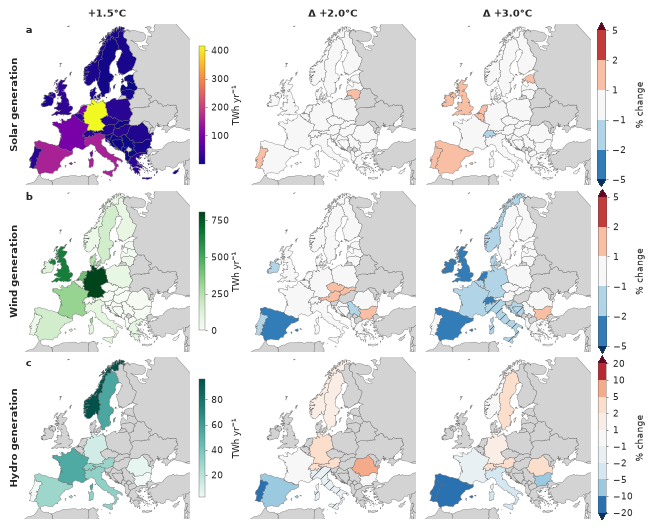

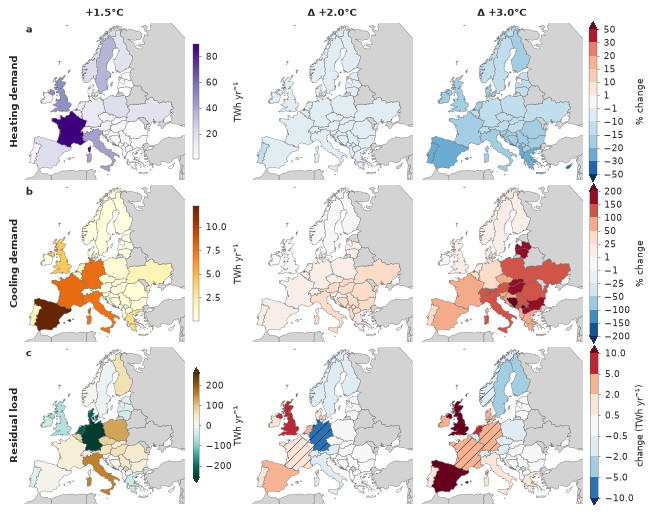

In [14]:
# Two 3 x 3 grids at full width: Europe is nearly square on the equal-area projection, so with
# three rows the maps fill 180 mm (~46 mm each) instead of letterboxing as the 6-row grid did.
FIG2_HEIGHT_MM = 125
FIG2_PARTS = {"fig2": FIG1_QUANTITIES[:3], "fig3": FIG1_QUANTITIES[3:]}   # supply | demand + RL
map_figures = {}
with publication_rc():
    for stem, quantities in FIG2_PARTS.items():
        fig, row_axes = mean_state_maps(
            quantities, countries_print, STYLE, compute_sign_agreement,
            height_mm=FIG2_HEIGHT_MM, width_mm=180, change_bins=FIG1_CHANGE_BINS,
            absolute_change_rows=FIG1_ABSOLUTE_ROWS, change_clabels=FIG1_CHANGE_CLABELS,
            # One-line headers; the caption defines the Δ once.
            column_titles=[REFERENCE, f"\u0394 {period_names[1]}", f"\u0394 {WARMEST}"])
        fig.get_layout_engine().set(h_pad=1 / 72, hspace=0.0)
        # Each colorbar label sits past its own tick labels; put each column's labels on one line.
        # Aligned BEFORE fitting the width (aligning pushes labels outward and widened the figure
        # to 181 mm), and again after, because the refit reflows the layout.
        for _ in range(2):
            align_colorbar_labels(fig, fig.change_colorbars)
            align_colorbar_labels(fig, fig.reference_colorbars)
            fit_width(fig, target_mm=179.5, max_height_mm=FIG2_HEIGHT_MM + 40)
        # Letters inside each map's empty top-left corner (the panel-letter rule's map exception).
        panel_letters(fig, list(zip("abc", row_axes)), inside=True)
        save(fig, stem, FIGS)
        map_figures[stem] = (fig, row_axes)

# ── The colorbar rules, checked on the RENDERED bars ────────────────────────────────────
# MaxNLocator picks round values, so the requested tick counts are targets, not guarantees:
# read them back off the drawn labels rather than trusting the locator.
# Count only ticks INSIDE each bar's value range. Labels alone are not enough: MaxNLocator
# emits round values beyond the data span, which are clipped from the drawing but still carry
# text, so a label count reports 4 where the figure shows 2.
fig, row_axes = map_figures["fig2"]
fig_rl, _ = map_figures["fig3"]
fig.canvas.draw()
fig_rl.canvas.draw()
tick_values = [[t for t in bar.get_ticks() if bar.norm.vmin <= t <= bar.norm.vmax]
               for bar in fig.reference_colorbars + fig_rl.reference_colorbars]
counts = [len(t) for t in tick_values]
assert counts[:-1] == [4] * (len(counts) - 1),         f"reference colorbars a-e should carry 4 ticks, got {counts[:-1]}"
assert counts[-1] == 5, f"the residual-load colorbar should carry 5 ticks, got {counts[-1]}"
assert sum(abs(t) < 1e-9 for t in tick_values[-1]) == 1,         f"the residual-load colorbar must mark zero exactly once: {tick_values[-1]}"

# "Same padding" is set as the same `pad` value, but matplotlib scales pad by the width of the
# PARENT axes, and the change bar has two parents to column 0's one. Report both gaps so the
# difference between equal-parameter and equal-appearance is visible rather than assumed.
gap0 = (fig.reference_colorbars[0].ax.get_position().x0
        - row_axes[0].get_position().x1)
gapc = (fig.change_colorbars[0].ax.get_position().x0
        - fig.axes[2].get_position().x1)
print()
print(f"Colorbar ticks per row: {counts}   (zero marked once on the last)")
print(f"Rendered colorbar gap: column 0 {gap0:.4f} vs change {gapc:.4f} of figure width")
assert abs(gap0 - gapc) < 0.004,         f"the two colorbars sit at different distances: {gap0:.4f} vs {gapc:.4f}"
plt.show()


In [15]:
# ── Numbers behind Figures 2 and 3 · the change, by balancing zone and Europe-wide ─────────────
# Estimator: per chain, sum the countries of the group, form THAT chain's change, then take the
# ensemble median. This is the map's estimator (median of per-chain changes), NOT the
# difference-of-medians used for the Europe totals in paper_main_figures_v2.ipynb. Both are
# legitimate and they differ wherever the ensemble is skewed, so the gap is printed below rather
# than left to be discovered. Summing per chain first also keeps the median a median of a physical
# quantity rather than of two medians.
from cordex2energy.conversion_energy.tyndp import REALTIME_BALANCING_ZONES

TABLE_COLUMNS = [name for name, *_ in FIG1_QUANTITIES]


def _group_change(field, members=None):
    '''Median across chains of the per-chain change. Returns (percent, absolute).

    `members=None` means every country the field carries.
    '''
    ref, warm = field(REFERENCE), field(WARMEST)
    if members is not None:
        available = set(map(str, ref["country"].values))
        present = [c for c in members if c in available]
        if not present:
            return np.nan, np.nan
        ref, warm = ref.sel(country=present), warm.sel(country=present)
    ref_total, warm_total = ref.sum("country", skipna=True), warm.sum("country", skipna=True)
    absolute = warm_total - ref_total
    # abs() in the denominator so a SHRINKING SURPLUS reads as a positive per cent: residual load
    # is signed, and a plain ratio would flip the sign for every group in surplus.
    percent = 100 * absolute / np.abs(ref_total)
    return float(percent.median("model")), float(absolute.median("model"))


rows, counts = {}, {}
for group, members in [*((ZONE_LABELS[z], REALTIME_BALANCING_ZONES[z]) for z in ZONE_ORDER),
                       ("Europe", None)]:
    entry = {}
    for name, field, *_ in FIG1_QUANTITIES:
        percent, absolute = _group_change(field, members)
        entry[name] = absolute if name in FIG1_ABSOLUTE_ROWS else percent
    rows[group] = entry
for name, field, *_ in FIG1_QUANTITIES:
    counts[name] = int(np.isfinite(field(REFERENCE).median("model").values).sum())

table1 = pd.DataFrame(rows).T[TABLE_COLUMNS]
print(f"Numbers behind Figures 2 and 3 · change from {REFERENCE} to {WARMEST}. Per cent except residual load, "
      f"which is an absolute change in TWh yr⁻¹.\n")
print(table1.round(1).to_string(na_rep="  n/a"))

Numbers behind Figures 2 and 3 · change from +1.5°C to +3.0°C. Per cent except residual load, which is an absolute change in TWh yr⁻¹.

               Solar generation  Wind generation  Hydro generation  Heating demand  Cooling demand  Residual load
Iberia                      1.6             -3.5             -16.5           -22.9            60.4            9.7
South-East                  0.4             -0.1              -2.5           -19.5            93.7            3.9
Central-West                0.7             -1.8               1.4           -15.9            40.5            1.2
Central-East                0.5             -0.1               1.4           -14.8           137.9           -2.2
Nordic                     -0.1             -1.1               1.7           -14.8             8.2           -4.9
British Isles               1.6             -2.8               n/a           -15.4             2.1           15.1
Europe                      0.7             -1.7              -0.4

In [16]:
# ── What the table's two conventions cost, stated rather than buried ────────────────────
# (1) Europe sums every country a variable carries, so it is NOT the sum of the six zone rows: the
#     demand product covers 37 countries while the zones cover 35.
# (2) The Europe row under the OTHER estimator, difference-of-medians, which is what
#     paper_main_figures_v2.ipynb prints and what the prose elsewhere quotes.
zone_rows = [ZONE_LABELS[z] for z in ZONE_ORDER]
zone_sum = table1.loc[zone_rows].sum()
in_zones = {c for z in ZONE_ORDER for c in REALTIME_BALANCING_ZONES[z]}

print("Europe row: how many countries it covers, and how it compares to the zone sum\n")
for name, field, *_ in FIG1_QUANTITIES:
    have = {str(c) for c, v in zip(field(REFERENCE)["country"].values,
                                   field(REFERENCE).median("model").values) if np.isfinite(v)}
    line = (f"  {name:<18} {counts[name]:3d} countries, "
            f"{len(have - in_zones):+d} outside the six zones")
    if name in FIG1_ABSOLUTE_ROWS:
        line += (f"   Europe {table1.loc['Europe', name]:+6.1f} vs zone sum "
                 f"{zone_sum[name]:+6.1f} TWh/yr")
    print(line)

print("\nEurope under both estimators:")
for name, field, *_ in FIG1_QUANTITIES:
    ref, warm = field(REFERENCE).sum("country"), field(WARMEST).sum("country")
    dom_ref, dom_warm = float(ref.median("model")), float(warm.median("model"))
    dom = ((dom_warm - dom_ref) if name in FIG1_ABSOLUTE_ROWS
           else 100 * (dom_warm - dom_ref) / abs(dom_ref))
    mod = float(table1.loc["Europe", name])
    unit = "TWh/yr" if name in FIG1_ABSOLUTE_ROWS else "%"
    print(f"  {name:<18} median-of-differences {mod:+7.1f}   "
          f"difference-of-medians {dom:+7.1f}   gap {abs(mod - dom):5.1f} {unit}")

# The caption states that no country crosses between surplus and deficit. Assert it, so a future
# run that DOES produce a crossing fails here instead of shipping a caption that says otherwise.
_rl = dict((q[0], q[1]) for q in FIG1_QUANTITIES)["Residual load"]
_ref_sign = np.sign(_rl(REFERENCE).median("model").values)
for _period in period_names[1:]:
    _warm_sign = np.sign(_rl(_period).median("model").values)
    _both = np.isfinite(_ref_sign) & np.isfinite(_warm_sign)
    _flipped = [str(c) for c, a, b in zip(_rl(REFERENCE)["country"].values, _ref_sign, _warm_sign)
                if np.isfinite(a) and np.isfinite(b) and a != b]
    assert not _flipped, f"residual load changes sign at {_period} in {_flipped}; caption is stale"
print(f"\nNo country changes sign between surplus and deficit at any warming level "
      f"({int(np.isfinite(_ref_sign).sum())} countries checked).")

Europe row: how many countries it covers, and how it compares to the zone sum

  Solar generation    35 countries, +0 outside the six zones
  Wind generation     35 countries, +0 outside the six zones
  Hydro generation    11 countries, +0 outside the six zones
  Heating demand      37 countries, +2 outside the six zones
  Cooling demand      37 countries, +2 outside the six zones
  Residual load       35 countries, +0 outside the six zones   Europe  +22.3 vs zone sum  +22.8 TWh/yr

Europe under both estimators:
  Solar generation   median-of-differences    +0.7   difference-of-medians    +1.2   gap   0.4 %
  Wind generation    median-of-differences    -1.7   difference-of-medians    -1.7   gap   0.0 %
  Hydro generation   median-of-differences    -0.4   difference-of-medians    -0.8   gap   0.4 %
  Heating demand     median-of-differences   -16.0   difference-of-medians   -15.1   gap   0.9 %
  Cooling demand     median-of-differences   +65.6   difference-of-medians   +65.5   gap   0.0

## 4 · Figure 4: the Europe-wide change, demand against supply

Added after internal review, which expected the climate-driven demand change to dominate Europe-wide.
Tested first: **annually it does not.** Falling heating and rising cooling largely cancel, and the
fall in wind generation is what raises the residual load. **In summer it does**: rising cooling
demand drives a residual-load increase that every chain agrees on. The figure shows both.

> **Figure 4 | Change in Europe-wide energy quantities between +1.5 °C and +3.0 °C.** **a**, Annual;
> **b**, winter (December–February, DJF); **c**, summer (June–August, JJA). Each row is a quantity
> summed over the 35 countries of the power-system model and the change is formed per chain: the
> darker box gives the interquartile range across the nine chains, its paler extensions the minimum to
> maximum, and the dark line the median. Demand is orange and supply blue, lighter for the components
> and darker for the totals; the residual load is grey. Heating and cooling demand are the thermal drivers from the demand
> model; total demand is the demand the residual load is computed from. Supply is solar, wind (on-
> and offshore) and hydro (run-of-river and reservoir dispatch); total supply also includes battery
> dispatch. The residual load is total demand minus total supply in every chain. Winter and summer
> share one axis. Table 1 gives the values; Supplementary Fig. S24 resolves the figure by balancing
> zone.


Europe-wide changes [5s]
               Annual    DJF    JJA
               median median median
Heating demand  -67.8  -20.2   -5.1
Cooling demand   33.6    0.0   29.0
Total demand    -22.7  -17.1   25.7
Solar             8.7   -1.7    5.9
Wind            -63.3  -12.6  -22.7
Hydro            -1.4   -1.3   -0.8
Total supply    -47.4   -9.0  -15.5
Residual load    22.3   -9.2   42.7
  fig4                         179.7 x  82.5 mm   panel 57.2 mm   pdf 37 kB  png 139 kB


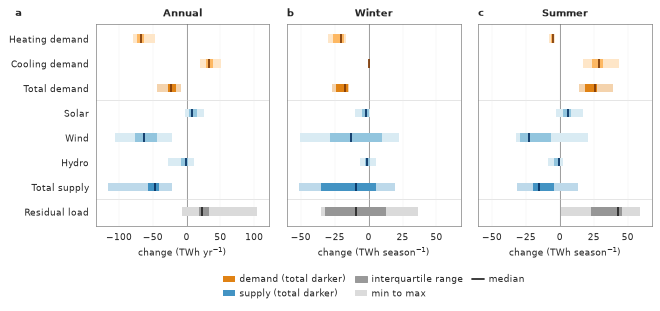

In [18]:
# ── Figure 4 · the Europe-wide change, demand against supply ────────────────────────────
# Tested before it was drawn: the review expected climate-driven demand to dominate the Europe-wide
# change. Annually it does not -- falling heating (-68 TWh/yr) and rising cooling (+34) cancel, and
# falling wind (-63) is what lifts the residual load. In summer it does: cooling drives the rise.
# So the figure shows both and the caption says which is which.
#
# Estimator as the numbers behind Figures 2 and 3: per chain, sum every country, form THAT chain's change, then the quartiles
# across chains. Heating and cooling come from the demand product, restricted to the residual-load
# run's countries; every other row is from that run, so the demand rows are the thermal DRIVERS, and
# "Total demand" is the demand the residual load actually subtracts supply from. The table and the figure are
# module builders shared with the zonal breakdown, Supplementary Fig. S24.
EUROPE_COLUMNS = {"Annual": None, "DJF": SEASON_MONTHS["DJF"], "JJA": SEASON_MONTHS["JJA"]}
_SUPPLY = ("gen_pv", "gen_wind_on", "gen_wind_off", "gen_hydro_ror", "reservoir_dispatch_gwh",
           "battery_dispatch_gwh")


def _country(expression):
    return lambda p, m: compute_country_gwl_field(country_output_by_model, period_defs, p,
                                                  expression, months=m)


# The thermal rows are summed over the residual-load run's countries ONLY, so every row covers one
# domain: the demand product also carries Ukraine and Kosovo (~7 % of European cooling), which no
# balancing zone and no power-system row includes.
RUN_COUNTRIES = [str(c) for c in country_output_by_model[models[0]]["country"].values]


def _demand(variable):
    def field(p, m):
        out = compute_c2e_gwl_field(demand_by_month, period_defs, p, variable, scale=24e-3, months=m)
        missing = set(RUN_COUNTRIES) - set(map(str, out["country"].values))
        assert not missing, f"run countries missing from the demand product: {sorted(missing)}"
        return out.sel(country=RUN_COUNTRIES)
    return field


EUROPE_ROWS = [
    ("Heating demand", _demand("heating")),
    ("Cooling demand", _demand("cooling")),
    ("Total demand", _country(lambda d: d["total_demand"])),
    ("Solar", _country(lambda d: d["gen_pv"])),
    ("Wind", _country(lambda d: d["gen_wind_on"] + d["gen_wind_off"])),
    ("Hydro", _country(lambda d: d["gen_hydro_ror"] + d["reservoir_dispatch_gwh"])),
    ("Total supply", _country(lambda d: sum(d[v] for v in _SUPPLY))),
    ("Residual load", _country(lambda d: d["residual_load"])),
]
EUROPE_LABELS = [label for label, _ in EUROPE_ROWS]

started = time.perf_counter()
europe_change = europe_change_table(EUROPE_ROWS, EUROPE_COLUMNS, REFERENCE, WARMEST)
print(f"Europe-wide changes [{time.perf_counter() - started:.0f}s]")

# The identity the figure's reading rests on, per chain: dRL = dDemand - dSupply exactly.
for column in EUROPE_COLUMNS:
    gap = (europe_change[column, "Residual load"].twh
           - (europe_change[column, "Total demand"].twh - europe_change[column, "Total supply"].twh)).abs()
    scale = max(1.0, float(europe_change[column, "Total demand"].twh.abs().max()))
    assert float(gap.max()) < 1e-6 * scale, \
        f"{column}: residual load is no longer demand minus supply ({float(gap.max()):.3g} TWh)"

europe_table = pd.DataFrame({(column, stat): {label: getattr(europe_change[column, label].twh, stat)()
                                              for label in EUROPE_LABELS}
                             for column in EUROPE_COLUMNS for stat in ("median",)})
print(europe_table.round(1).to_string())


def _agree(series):
    return int((np.sign(series) == np.sign(series.median())).sum())


# The three claims the caption makes, asserted where the numbers are.
_ann = {k: europe_change["Annual", k].twh.median() for k in ("Total demand", "Total supply")}
assert abs(_ann["Total supply"]) > abs(_ann["Total demand"]), \
    f"annually demand now outweighs supply: {_ann}"
assert europe_change["JJA", "Residual load"].twh.median() > 0 \
    and _agree(europe_change["JJA", "Residual load"].twh) >= 8, "summer residual load no longer rises robustly"
assert europe_change["JJA", "Total demand"].twh.median() > abs(europe_change["JJA", "Total supply"].twh.median()), \
    "summer demand no longer outweighs the summer supply change"

with publication_rc():
    fig = europe_change_figure(europe_change, EUROPE_LABELS, EUROPE_COLUMNS, value="twh")
    save(fig, "fig4", FIGS)
plt.show()


### Table 1

> **Table 1 | Change in Europe-wide energy quantities between +1.5 °C and +3.0 °C, by time scale.**
> The values Figure 4 draws. **a**, Annual (TWh yr⁻¹); **b**, winter (December–February, DJF) and
> **c**, summer (June–August, JJA), in TWh season⁻¹. Each quantity is summed over the 35 countries
> of the power-system model and the change is formed per chain; the columns give the median,
> quartiles (P25, P75), minimum and maximum across the nine chains, and the number of chains whose
> change has the sign of the median. A dash marks a median change below 0.05 TWh, whose sign carries
> no information.


In [20]:
# ── Table 1 · the values Figure 4 draws, one table per time scale ───────────────────────
# Built from the SAME per-chain table as the figure (`europe_change`), so the two cannot disagree,
# and written as CSV beside the figure for the manuscript.
TABLE1_PARTS = {"Annual": "a · annual (TWh yr⁻¹)", "DJF": "b · winter, DJF (TWh season⁻¹)",
                "JJA": "c · summer, JJA (TWh season⁻¹)"}
europe_summary = europe_change_summary(europe_change, EUROPE_LABELS, EUROPE_COLUMNS)
for column, frame in europe_summary.items():
    print(f"Table 1{TABLE1_PARTS[column]}\n")
    print(markdown_table(frame, index_label="quantity"), end="\n\n")
pd.concat(europe_summary, names=["time scale", "quantity"]).to_csv(
    FIGS / "table1_europe_change.csv", float_format="%.2f")

# The table restates the figure: its medians are the ones the Figure 4 asserts above test.
assert europe_summary["JJA"].loc["Residual load", "sign agreement"] == "9/9"


Table 1a · annual (TWh yr⁻¹)

| quantity | median | P25 | P75 | min | max | sign agreement |
|:---|---:|---:|---:|---:|---:|---:|
| Heating demand | −67.8 | −72.8 | −62.7 | −79.7 | −47.5 | 9/9 |
| Cooling demand | +33.6 | +29.3 | +38.4 | +20.4 | +50.3 | 9/9 |
| Total demand | −22.7 | −27.7 | −16.1 | −44.0 | −8.1 | 9/9 |
| Solar | +8.7 | +4.2 | +16.1 | −1.9 | +26.1 | 8/9 |
| Wind | −63.3 | −75.6 | −44.2 | −106.4 | −21.8 | 9/9 |
| Hydro | −1.4 | −7.9 | +2.5 | −27.8 | +11.6 | 6/9 |
| Total supply | −47.4 | −57.0 | −41.3 | −116.9 | −22.2 | 9/9 |
| Residual load | +22.3 | +19.0 | +33.2 | −7.5 | +104.9 | 8/9 |

Table 1b · winter, DJF (TWh season⁻¹)

| quantity | median | P25 | P75 | min | max | sign agreement |
|:---|---:|---:|---:|---:|---:|---:|
| Heating demand | −20.2 | −26.1 | −17.9 | −29.8 | −16.4 | 9/9 |
| Cooling demand | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | – |
| Total demand | −17.1 | −23.9 | −15.2 | −26.8 | −14.7 | 9/9 |
| Solar | −1.7 | −5.1 | +0.2 | −10.1 | +0.9 | 6/9 |
| Wind | −12.6 

## 5 · Figure 5: where the deficit tail is, and how it is distributed over event duration

> **Figure 5 | The deficit burden moves from winter to summer.**
> **a**, The six real-time balancing zones used throughout; countries outside the modelled set are
> grey. Equal-area ETRS89-LAEA projection (EPSG:3035).
> **b**, Exceedance (survival) curves of the zonal residual load, P(RL > x), for the two southern
> zones in winter (DJF, upper) and summer (JJA, lower). Lines are the ensemble median over nine chains,
> shading the interquartile range; colour denotes warming level. The dashed line and grey band mark the
> CERRA p95 deficit threshold, which is absolute and season-independent, so all three warming levels
> are judged against one fixed yardstick. Annotations give the factor by which the probability of
> exceeding that threshold changes between +1.5 °C and +3.0 °C. The other four zones and the
> shoulder seasons are Supplementary Fig. S28.
> **c**, Extreme events per year across Europe by event duration, summed within each chain before
> the ensemble median is taken. **d**, The severity of those same events — the energy above the
> threshold — on the same duration axis. Shading is the interquartile range across the nine chains. The
> dashed rule marks the 24 h boundary between the paper's two duration classes, placed between the
> 12–24 h and 1–2 d bins. Supplementary Fig. S29 resolves **c** and **d** by balancing zone.

  fig5                         179.9 x 124.6 mm   panel 44.4 mm   pdf 182 kB  png 674 kB

Panel c, events per year by duration bin (median across chains):
  0-6 h    +1.5°C  25.05  +2.0°C  25.45  +3.0°C  30.90
  6-12 h   +1.5°C  21.00  +2.0°C  23.00  +3.0°C  30.70
  12-24 h  +1.5°C  25.45  +2.0°C  30.00  +3.0°C  33.75
  1-2 d    +1.5°C   8.45  +2.0°C   9.10  +3.0°C   8.90
  2-4 d    +1.5°C   6.85  +2.0°C   6.60  +3.0°C   6.95
  4-8 d    +1.5°C   3.30  +2.0°C   3.25  +3.0°C   3.25
  8-16 d   +1.5°C   0.80  +2.0°C   0.75  +3.0°C   0.70
  > 16 d   +1.5°C   0.10  +2.0°C   0.20  +3.0°C   0.15

Events per year added, +1.5°C -> +3.0°C: sub_daily +23.85  multi_day +0.45
Severity peaks in the '2-4 d' bin at 3.2 TWh/yr, while the counts peak in '12-24 h'

Exceedance ratio at the threshold, +1.5 to +3.0 (what panel b annotates):
  Iberia      DJF  x1.7
  Iberia      JJA  x6.4
  South-East  DJF  x0.9
  South-East  JJA  x11.2


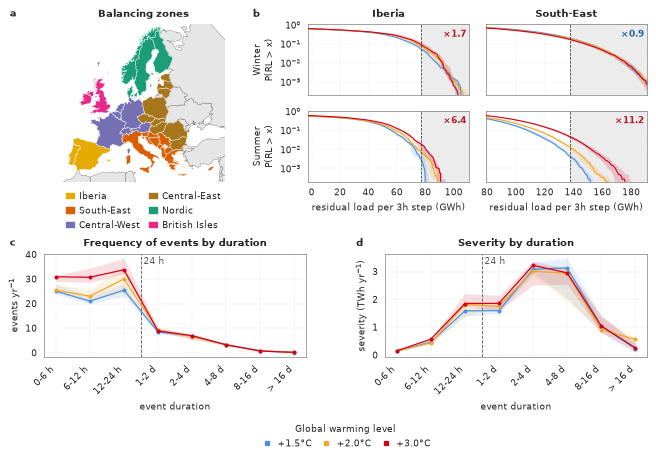

In [22]:
# ── Figure 5: the zones, the tail against the threshold, and the duration split ─────────
# Built by `zone_tail_duration_figure` in plotting_publication, which the options notebook also
# calls for its layout and map-width sweep — one builder, so the comparison and the shipped figure
# cannot diverge.
DURATION_EDGES = [0, 6, 12, 24, 48, 96, 192, 384, 1e4]
DURATION_BIN_LABELS = ["0-6 h", "6-12 h", "12-24 h", "1-2 d", "2-4 d", "4-8 d", "8-16 d", "> 16 d"]
SOUTHERN_ZONES = ["Iberian_Peninsula", "South_East"]


def duration_spectrum(value):
    """Events, or severity, per chain-year in each duration bin — one row per chain and level."""
    rows = []
    for (model, period), block in storage_events.groupby(["model", "period"]):
        for lo, hi, label in zip(DURATION_EDGES[:-1], DURATION_EDGES[1:], DURATION_BIN_LABELS):
            inside = block[(block.duration_h > lo) & (block.duration_h <= hi)]
            rows.append(dict(model=model, period=period, bin=label,
                             value=(len(inside) if value == "counts"
                                    else inside.sev_actual.sum() / 1e3) / 20.0))
    return pd.DataFrame(rows)


with publication_rc():
    fig = zone_tail_duration_figure(
        countries=countries_print, residual_load_by_model=residual_load_by_model,
        period_defs=period_defs, zone_threshold=zone_threshold, season_months=SEASON_MONTHS,
        style=STYLE, southern_zones=SOUTHERN_ZONES, seasons=MAIN_SEASONS, spread=SPREAD,
        zone_members=REALTIME_BALANCING_ZONES, zone_colors=ZONE_COLORS,
        duration_spectrum=duration_spectrum, bin_labels=DURATION_BIN_LABELS,
        # 0.74 was chosen from the rendered width sweep in paper_figure_options.ipynb, when the map
        # was stretched to fill its cell. It is now drawn at equal aspect on the equal-area
        # projection (to scale, as the caption says), so the cell only sets how much white frames it.
        layout="beside", map_share=0.74)
    # c and d are the same kind of plot and must be the same size; the nested bottom row is what
    # guarantees it, and this is the check that fails if that nesting is ever undone.
    _c, _d = fig.axes[-2].get_position().width, fig.axes[-1].get_position().width
    assert abs(_c - _d) < 1e-9, f"Figure 5's panels c and d differ in width ({_c:.4f} vs {_d:.4f})"
    save(fig, "fig5", FIGS)
plt.show()

# The caption's two headline numbers for panels c and d, measured off the very table they are
# drawn from rather than read back off the picture.
_counts = duration_spectrum("counts").groupby(["period", "bin"])["value"].median()
_severity = duration_spectrum("severity").groupby(["period", "bin"])["value"].median()
_SUB_DAILY_BINS = DURATION_BIN_LABELS[:3]          # 0-6 h, 6-12 h, 12-24 h
_MULTI_DAY_BINS = DURATION_BIN_LABELS[3:]
print("\nPanel c, events per year by duration bin (median across chains):")
for _label in DURATION_BIN_LABELS:
    print(f"  {_label:<9}" + "  ".join(f"{_p} {_counts[(_p, _label)]:6.2f}" for _p in period_names))
_added = {name: sum(_counts[(WARMEST, b)] - _counts[(REFERENCE, b)] for b in bins)
          for name, bins in (("sub_daily", _SUB_DAILY_BINS), ("multi_day", _MULTI_DAY_BINS))}
print(f"\nEvents per year added, {REFERENCE} -> {WARMEST}: "
      + "  ".join(f"{k} {v:+.2f}" for k, v in _added.items()))
assert _added["sub_daily"] > 10 * abs(_added["multi_day"]), (
    "Figure 5's caption says essentially the whole increase is sub-daily; that no longer holds by "
    f"even a factor of ten: {_added}")

# Panel d's point: the severity peak is NOT in the bins that multiply.
_peak = max(DURATION_BIN_LABELS, key=lambda b: _severity[(WARMEST, b)])
print(f"Severity peaks in the {_peak!r} bin at {_severity[(WARMEST, _peak)]:.1f} TWh/yr, "
      f"while the counts peak in "
      f"{max(DURATION_BIN_LABELS, key=lambda b: _counts[(WARMEST, b)])!r}")
assert _peak in _MULTI_DAY_BINS, (
    f"Figure 5's caption says the energy sits in multi-day events, but severity now peaks in "
    f"{_peak!r}, a sub-daily bin")

print("\nExceedance ratio at the threshold, +1.5 to +3.0 (what panel b annotates):")
for _zone in SOUTHERN_ZONES:
    _thr = float(zone_threshold.sel(zone=_zone))
    for _season in MAIN_SEASONS:
        _ref = compute_exceedance_probability(residual_load_by_model, period_defs, _zone,
                                              SEASON_MONTHS[_season], REFERENCE, _thr)
        _warm = compute_exceedance_probability(residual_load_by_model, period_defs, _zone,
                                               SEASON_MONTHS[_season], WARMEST, _thr)
        print(f"  {ZONE_LABELS[_zone]:<12}{_season}  x{_warm / _ref:.1f}" if _ref > 0
              else f"  {ZONE_LABELS[_zone]:<12}{_season}  n/a")


## 6 · Figure 6: the sub-daily regime

> **Figure 6 | Short evening and overnight deficits multiply in Southern Europe.**
> **a**, Sub-daily (≤ 24 h) extreme events per year by balancing zone and warming level. Boxes span
> the interquartile range across the nine chains, whiskers extend to 1.5×IQR and the line is the
> median. Annotations give the median of the nine chains' own changes from +1.5 °C to +3.0 °C, and
> the number of chains whose change carries that sign. The median is taken of the changes, not of
> the levels, so it is not the ratio of the two medians drawn.
> **b**, The same change resolved by season (rows) and balancing zone (columns), in events yr⁻¹.
> Colour classes are discrete, set for this duration class alone, and widen toward +8 events yr⁻¹
> so that no cell saturates. Cells are hatched where
> fewer than six of nine chains agree on the sign; cells marked *none* have no events of this class
> in that season in any chain at either level, which is a different statement from a change of zero.
> A column is read season by season and not summed against the annotation in **a**: four medians need
> not sum to the median of their total.
> **c**, Hours per year above the p95 threshold by hour of day, pooled over Iberia and the
> South-East, summer (JJA, upper) above winter (DJF, lower). Lines are ensemble medians and shading the
> interquartile range; the shaded vertical bands mark the evening and overnight windows.
> **d**, Contribution of each supply and demand driver to the change in residual load between
> +1.5 °C and +3.0 °C, as diverging stacked bars, for the two zones **c** pools; season is a
> labelled position under each stack; the arrows mark the sign convention (up deepens the deficit,
> down eases it). Black diamonds give the net change with its interquartile range and
> hatching is as in **b**. The window is both shaded bands of **c**, evening and overnight together
> — everything but the midday PV hours, which is where these events sit: at +3.0 °C only 44 % of
> Iberia's sub-daily event timesteps fall in the evening band against 53 % overnight. The other four
> zones are Supplementary Fig. S30.

In [24]:
# ── Panel titles, every one checked against the tables above ────────────────────────────
# Fig 6a: Iberia 13.1 -> 24.6 events/yr, South-East 20.2 -> 27.1. The ANNOTATED percentages are the
#         median of each chain's own change, not the ratio of those medians: Iberia +118 % (9/9
#         chains), South-East +42 % (9/9). The unpaired reading would give +87 % and +34 %; the two
#         differ because the median chain is not the same one at both levels, and Central-West even
#         changes sign between them (-3 % unpaired against +7 % paired). See paired_change_pct.
# Fig 6b: southern JJA at +3.0 C runs 39 h/yr at 18:00 and 17 h/yr at 00:00, ~0 at 06-12.
# Supplementary Fig. S31a: Europe total 19.6 -> 20.4 events/yr (flat); paired changes Central-East -20 %,
#         Nordic -15 %, British Isles +33 %.
# Supplementary Fig. S31b: South-East DJF 4.95 -> 4.45 while its JJA goes 0.00 -> 0.75.
# Supplementary Fig. S31d: NOT "absorbs least where events are longest" that fails (South-East 106 h absorbs
#         71.5 % while Central-East 69 h absorbs 36.3 %). What holds in EVERY zone is that the
#         battery share shrinks from sub-daily to multi-day (South-East 68.5 -> 48.4,
#         Central-West 60.4 -> 34.5, Central-East 20.3 -> 6.0, British Isles 69.7 -> 39.9).
# Titles NAME THE QUANTITY; the y-label carries the unit; a panel showing a change names the two
# periods it compares. The findings these titles used to assert live in the captions, which state
# them with their agreement counts — a title cannot carry "9 of 9 chains" and should not imply it.
# "extreme events" throughout, matching the paper's own title rather than the older "extreme event".
# Only the sub-daily regime is a main figure now; the multi-day one is Supplementary Fig. S31 and
# takes its titles from the SI notebook, which builds it from the SAME module builder.
FIG_TITLES = {
    "sub_daily": {
        "a": "Sub-daily extreme events",
        "b": f"Change in events by season and zone, {REFERENCE} to {WARMEST}",
        "c": "Exceedance by hour of day, southern zones",
        # No ", southern zones": panel c beside it already says so and d prints the two zone names
        # under its own bars. Spelling out the wider window made this title long enough to push the
        # tight bounding box to 181.8 mm, over the 180 mm column.
        "d": f"Evening and overnight drivers, {REFERENCE} to {WARMEST}",
    },
    "multi_day": {
        "a": "Multi-day extreme events",
        "b": f"Change in events by season and zone, {REFERENCE} to {WARMEST}",
        "c": f"Driver decomposition by season, {REFERENCE} to {WARMEST}",
    },
}
# One bin set per duration class: measured over the 24 cells of each grid, sub-daily runs -0.90 to
# +7.90 events/yr and multi-day only -0.80 to +0.70, so a shared ramp would put every multi-day
# cell in the neutral class. The two panels sit in different figures whose panel-a axes are already
# 0-30 and 0-7, so no reader is being invited to compare cell colours across them.
SEASON_BINS = {"sub_daily": SEASON_COUNT_BINS_SUB_DAILY,
               "multi_day": SEASON_COUNT_BINS_MULTI_DAY}
# Figure 6's second row is about the south: panel c pools the southern zones, so panel d beside it
# decomposes the same zones. The other four are Supplementary Fig. S30.
SOUTHERN_ZONES = ["Iberian_Peninsula", "South_East"]
# Figures 7 and 8 carry DESCRIPTIVE titles rather than the finding-stating ones of Figures 2-6.
# Neither figure's headline is a property of a single panel: Figure 7's is the contrast between its
# two panels and Figure 8's is the contrast between its two build-outs, and a title that states a
# finding the panel below it does not on its own show is worse than one that names the quantity.
# SHORT class labels, for axis ticks and table headers. Deliberately NOT called
# DURATION_LABELS: that name is the two-line form Figure 5b's sub-panel titles need, set in
# the configuration cell, and one name for both meant this cell silently redefined it for
# every cell after it — Figure 5 only escaped because it is drawn earlier.
# No space around the number: the two labels share a 15.8 mm zone slot in Figure 7a and at
# "\u2264 24 h" (~9 mm each) they overlapped whatever the bar spacing. "\u226424h" is ~6.5 mm.
# \u22641d / >1d since the move to 7 pt: \u226424h beside >24h fused into one word again.
CLASS_LABELS = {"sub_daily": "\u22641d", "multi_day": ">1d"}
STORAGE_TITLES = {"a": "Balanced share by zone and duration class",
                  "b": "Unbalanced severity, Europe total"}
SCENARIO_TITLES = {"a": "Sub-daily extreme events",
                   "b": "Multi-day extreme events"}
EVENING_WINDOW, EVENING_LABEL = (15, 21.8), "evening"
NIGHT_WINDOW, NIGHT_LABEL = (-0.8, 6.0), "night"


# `attribution_change_by_model` builds column names by replacing spaces with underscores, so the
# palette keys must stay the pipeline's names. The rename is applied at the legend only.

# `regime_figure` moved into plotting_publication: the multi-day regime is now a supplementary
# figure, so one builder is called from two notebooks and a local copy here would drift from it.
def figure_sub_daily():
    return regime_figure(
        "sub_daily",
        events_annual=events_annual, events_by_season=events_by_season, style=STYLE,
        titles=FIG_TITLES["sub_daily"], season_bins=SEASON_BINS["sub_daily"],
        seasons=SEASON_ORDER,
        attribution=lambda zone, season: attribution_change_by_model(
            evening_peak_components, zone, season, REFERENCE, WARMEST, STYLE.drivers),
        # Two seasons only: the attribution is defined on the window panel c resolves, and
        # compute_evening_peak_attribution carries no others.
        driver_seasons=list(MAIN_SEASONS),
        # The southern zones alone, so the second row keeps one subject — panel c pools exactly
        # these two. The other four are Supplementary Fig. S30, paired with their own diurnal
        # profiles.
        driver_zones=SOUTHERN_ZONES,
        diurnal=southern_hours,
        diurnal_windows=dict(evening=EVENING_WINDOW, night=NIGHT_WINDOW,
                             evening_label=EVENING_LABEL, night_label=NIGHT_LABEL),
        driver_display=DRIVER_DISPLAY)


  fig6                         179.9 x 130.9 mm   panel 38.9 mm   pdf 113 kB  png 496 kB

Southern exceedance hours at +3.0°C falling in the window panel d decomposes:
  deficit window (0, 3, 6, 15, 18, 21): 94.2%
  evening peak   (15, 18, 21): 60.8%
  Iberia         DJF  net   +3.5  largest driver Reservoir Hydro
  Iberia         JJA  net   +6.8  largest driver Demand
  South-East     DJF  net   -5.9  largest driver Demand
  South-East     JJA  net  +14.0  largest driver Demand


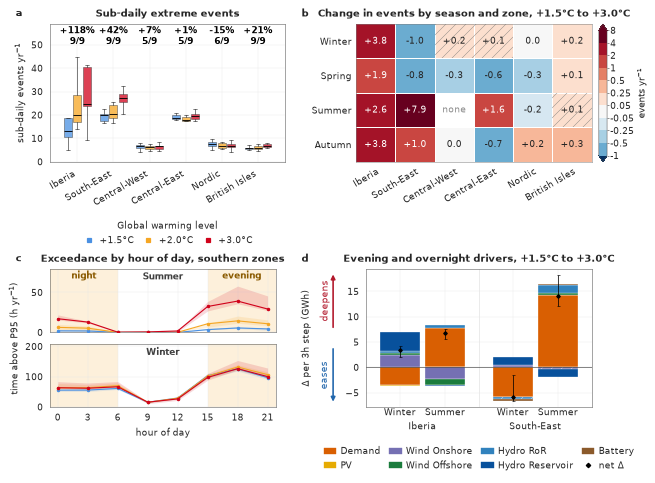

In [25]:
with publication_rc():
    fig = figure_sub_daily()
    save(fig, "fig6", FIGS)
    # All four panels the same width, which is what the even bottom row buys back.
    _widths = {round(ax.get_position().width, 6) for ax in fig.axes[:2]}
    assert len(_widths) == 1, f"Figure 6's top row panels differ in width: {_widths}"
plt.show()

# ── Why panel d's window is both shaded bands of panel c, and not the evening alone ────────
# Panel c plots exceedance hours by hour of day; panel d decomposes the drivers over a window of
# those hours. The two only describe the same thing if the window covers the hours c shows the
# deficit in. It does not, if the window is the evening peak alone — these events run 10-14 h and
# spill into the night — so the window is both bands, everything but the midday PV hours.
_south_warm = southern_hours[(southern_hours.period == WARMEST)
                             & southern_hours.season.isin(MAIN_SEASONS)]
_share = (_south_warm.groupby("hour")["hours_yr"].sum()
          / _south_warm["hours_yr"].sum())
_in_deficit = float(_share[_share.index.isin(DEFICIT_WINDOW_HOURS)].sum())
_in_evening = float(_share[_share.index.isin(EVENING_PEAK_HOURS)].sum())
print(f"\nSouthern exceedance hours at {WARMEST} falling in the window panel d decomposes:")
print(f"  deficit window {DEFICIT_WINDOW_HOURS}: {100 * _in_deficit:.1f}%")
print(f"  evening peak   {EVENING_PEAK_HOURS}: {100 * _in_evening:.1f}%")
assert _in_deficit >= 0.90, (
    f"panel d's window no longer covers the deficit panel c draws ({100 * _in_deficit:.1f}% < 90%); "
    "the two panels would be describing different hours")

# The widening must not move the argument, only sharpen which hours it rests on: summer demand is
# the caption's claim for both southern zones, and the four net changes keep their signs.
_expected_sign = {("Iberian_Peninsula", "DJF"): +1, ("South_East", "DJF"): -1,
                  ("Iberian_Peninsula", "JJA"): +1, ("South_East", "JJA"): +1}
for _zone in SOUTHERN_ZONES:
    for _season in MAIN_SEASONS:
        _pc = attribution_change_by_model(evening_peak_components, _zone, _season,
                                          REFERENCE, WARMEST, STYLE.drivers)
        _med = _pc.median()
        _net, _top = float(_med["net"]), max(STYLE.drivers, key=lambda d: abs(_med[d]))
        print(f"  {ZONE_LABELS[_zone]:<14} {_season}  net {_net:+6.1f}  largest driver {_top}")
        assert np.sign(_net) == _expected_sign[(_zone, _season)], (
            f"{ZONE_LABELS[_zone]} {_season} net changed sign under the wider window: {_net:+.1f}")
        if _season == "JJA":
            assert _top == "Demand", (
                f"{ZONE_LABELS[_zone]} JJA is no longer demand-led ({_top}); Figure 6's caption "
                "and the main text both say cooling demand drives the southern summer increase")

## 7 · Figure 7: what storage balances, and what it leaves unbalanced

> **Figure 7 | Storage balances less as events lengthen, and most of what it leaves unbalanced is long events.**
> **a**, Share of extreme-event severity balanced by storage at +3.0 °C, per balancing zone and
> duration class (≤ 1 d and > 1 d), decomposed by a two-player Shapley split into a reservoir and a battery
> contribution; the two segments sum exactly to the combined attenuation. Error bars give the
> interquartile range across the nine chains on the combined total. The British Isles operate no reservoir
> fleet, so their battery provides all of the balancing in both classes.
> **b**, The severity of those events at +3.0 °C, resolved by event duration and split into the part
> storage balances and the part it leaves unbalanced — the absolute energy behind **a**'s percentage. Summed
> across zones within each chain and only then reduced across chains, so it is a physical European
> total rather than a sum of six medians. The dashed rule marks the 24 h class boundary of **a**,
> placed between the 12–24 h and 1–2 d bins.

  fig7                         179.7 x  69.5 mm   panel 38.9 mm   pdf 47 kB  png 208 kB

Combined absorption falls on long events in all six zones; the British Isles remain battery-only.


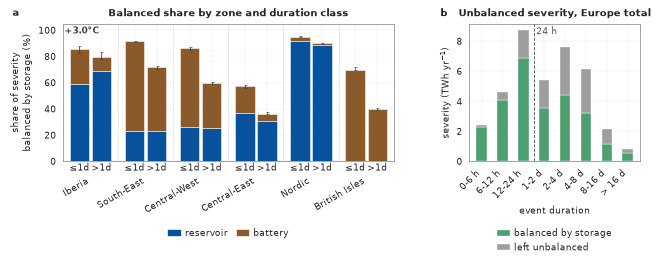

In [27]:
# ── Panel b's table: absorbed and unabsorbed energy, resolved by event DURATION ─────────
# Per-event rows, binned on length and summed per chain-year, so the panel is a distribution over
# the duration axis rather than a Europe total. `absorbed` is the counterfactual severity minus
# what actually happened — the energy storage took out.
DURATION_EDGES = [0, 6, 12, 24, 48, 96, 192, 384, 1e4]
DURATION_BIN_LABELS = ["0-6 h", "6-12 h", "12-24 h", "1-2 d", "2-4 d", "4-8 d", "8-16 d", "> 16 d"]

_rows = []
_events = storage_events.assign(absorbed=storage_events.sev_no_storage - storage_events.sev_actual)
for (_model, _period), _block in _events.groupby(["model", "period"]):
    for _lo, _hi, _label in zip(DURATION_EDGES[:-1], DURATION_EDGES[1:], DURATION_BIN_LABELS):
        _inside = _block[(_block.duration_h > _lo) & (_block.duration_h <= _hi)]
        _rows.append(dict(model=_model, period=_period, bin=_label,
                          sev_actual=_inside.sev_actual.sum() / 20.0 / 1e3,
                          absorbed=_inside.absorbed.sum() / 20.0 / 1e3))
severity_by_duration = pd.DataFrame(_rows)

# The identity the stack rests on: absorbed + unabsorbed is the counterfactual severity, exactly.
_check = _events.assign(total=_events.absorbed + _events.sev_actual)
assert np.allclose(_check.total, _check.sev_no_storage), \
    "the stacked bar does not close: absorbed + unabsorbed != severity without storage"

def figure_storage():
    """What storage absorbs, beside the energy it leaves behind."""
    # One panel row tall, the same axes height as the top row of Figure 6 and Supplementary Fig. S31, so the figures
    # read at one scale. Panel a carries twelve stacks and panel b six boxes, hence the ratio.
    # 1.15/0.85, not the 1.40/0.60 the old panel b used: that panel had two category ticks, this
    # one has eight rotated duration labels, and at 0.60 of the width they overhang the axes far
    # enough to push the TIGHT bbox to 181.4 mm — past the 180 mm rule `save` enforces. Widening
    # panel b pulls the overhang back inside.
    fig, axes = plt.subplots(1, 2, figsize=(WIDTH, PANEL_ROW_MM * MM),
                             gridspec_kw={"wspace": 0.30, "width_ratios": (1.45, 0.75)})   # a wider: its two class labels sit horizontal
    # The default group_span. Narrowing it was tried and is exactly backwards: `group_span` is the
    # fraction of the zone slot the stacks occupy, so a smaller value moves the two bar CENTRES
    # together and pushes their labels further into each other. The label length is the constraint,
    # and CLASS_LABELS is what was shortened.
    panel_storage_stack(axes[0], storage_attenuation, STYLE,
                        group_by=("duration_class", list(DURATION_BINS),
                                  [CLASS_LABELS[c] for c in DURATION_BINS]),
                        where={"period": WARMEST}, level_label=WARMEST)
    # Panel b is the ABSOLUTE energy, by duration bin — what panel a's percentage hides. Panel a
    # says Central-East absorbs 36 % of its multi-day severity; this says how many TWh that is and
    # where along the duration range the unabsorbed remainder accumulates. It replaces a
    # Europe-aggregate severity total whose only change statistic was a null under every estimator.
    positions = np.arange(len(DURATION_BIN_LABELS))
    block = severity_by_duration[severity_by_duration.period == WARMEST]
    absorbed = [block[block.bin == b]["absorbed"].median() for b in DURATION_BIN_LABELS]
    residual = [block[block.bin == b]["sev_actual"].median() for b in DURATION_BIN_LABELS]
    axes[1].bar(positions, absorbed, 0.50, color="#4C9F70", edgecolor="white", lw=0.3,
                label="balanced by storage", zorder=2)
    axes[1].bar(positions, residual, 0.50, bottom=absorbed, color="#9E9E9E", edgecolor="white",
                lw=0.3, label="left unbalanced", zorder=2)
    # The 24 h boundary is the class split panel a is drawn on, marked here so the two panels are
    # read against one another.
    axes[1].axvline(DURATION_BIN_LABELS.index("12-24 h") + 0.5, color="0.35", lw=0.7, ls="--",
                    zorder=1)
    axes[1].annotate("24 h", xy=(DURATION_BIN_LABELS.index("12-24 h") + 0.5, 1.0),
                     xycoords=("data", "axes fraction"), xytext=(2, -2),
                     textcoords="offset points", ha="left", va="top", fontsize=FS["tick"], color="0.35")
    axes[1].set_xticks(positions)
    axes[1].set_xticklabels(DURATION_BIN_LABELS, fontsize=FS["tick"], rotation=45, ha="right")
    axes[1].set_xlim(-0.6, len(DURATION_BIN_LABELS) - 0.4)
    axes[1].set_ylabel("severity (TWh yr$^{-1}$)", fontsize=FS["label"])
    axes[1].set_xlabel("event duration", fontsize=FS["label"])
    axes[1].tick_params(labelsize=FS["tick"])
    for letter, ax in zip("ab", axes):
        ax.set_title(STORAGE_TITLES[letter], fontsize=FS["title"], fontweight="bold")
    fit_width(fig)
    legend_below(fig, axes[0], *storage_handles(STYLE), ncol=2)
    # One column: panel b is narrower now, and two columns ran past the page edge.
    legend_below(fig, axes[1], *axes[1].get_legend_handles_labels(), ncol=1)
    panel_letters(fig, list(zip("ab", axes)))
    return fig


with publication_rc():
    fig = figure_storage()
    save(fig, "fig7", FIGS)
plt.show()

# The numbers themselves are printed in the next cell. Here only the claims that must HOLD.
# Combined absorption must fall from sub-daily to multi-day in every zone: that is panel a's
# headline and it is asserted rather than eyeballed. The battery SHARE claim is deliberately not
# asserted, because the British Isles have no reservoir and sit at 100 % in both classes.
for _zone in zones:
    _combined = []
    for _class in DURATION_BINS:
        _row = storage_attenuation[(storage_attenuation.duration_class == _class)
                                   & (storage_attenuation.period == WARMEST)
                                   & (storage_attenuation.zone == _zone)]
        _combined.append(_row["reservoir_attenuation_share_pct"].median()
                         + _row["battery_attenuation_share_pct"].median())
    assert _combined[1] < _combined[0], \
        f"{_zone}: absorption does not fall on long events ({_combined[0]:.1f} -> {_combined[1]:.1f})"
_bi = storage_attenuation[(storage_attenuation.zone == "British_Isles")
                          & (storage_attenuation.period == WARMEST)]
assert np.allclose(_bi["reservoir_attenuation_share_pct"].median(), 0.0), \
    "the British Isles now have a reservoir fleet; the caption's exception is stale"
print("\nCombined absorption falls on long events in all six zones; the British Isles remain "
      "battery-only.")


In [28]:
# ── Numbers behind Figure 7 · every number it draws ─────────────────────────────────────
# Panel a is a LEVEL at +3.0 °C and panel b is a level at each of the three, so neither table is a
# change table; the one change column that appears (panel b's) is the paired one, each chain's own
# ratio then the median, which is the estimator every percentage in this paper uses.
table_figure4_absorbed = pd.DataFrame(
    {(CLASS_LABELS[dc], part): {
        ZONE_LABELS[z]: storage_attenuation[
            (storage_attenuation.duration_class == dc)
            & (storage_attenuation.period == WARMEST)
            & (storage_attenuation.zone == z)][column].median()
        for z in zones}
     for dc in DURATION_BINS
     for column, part in [("reservoir_attenuation_share_pct", "reservoir"),
                          ("battery_attenuation_share_pct", "battery")]})
for dc in DURATION_BINS:
    label = CLASS_LABELS[dc]
    table_figure4_absorbed[(label, "combined")] = (table_figure4_absorbed[(label, "reservoir")]
                                                   + table_figure4_absorbed[(label, "battery")])
table_figure4_absorbed = table_figure4_absorbed[
    [(CLASS_LABELS[dc], part) for dc in DURATION_BINS
     for part in ("reservoir", "battery", "combined")]]
table_figure4_absorbed.columns = pd.MultiIndex.from_tuples(table_figure4_absorbed.columns)

_levels = severity_by_duration.groupby(["bin", "period"], observed=True)[
    ["absorbed", "sev_actual"]].median()
table_figure4_unabsorbed = pd.DataFrame({
    "absorbed (TWh yr⁻¹)": [_levels.loc[(b, WARMEST), "absorbed"] for b in DURATION_BIN_LABELS],
    "unabsorbed (TWh yr⁻¹)": [_levels.loc[(b, WARMEST), "sev_actual"] for b in DURATION_BIN_LABELS],
}, index=DURATION_BIN_LABELS)
table_figure4_unabsorbed["absorbed share (%)"] = (
    100 * table_figure4_unabsorbed["absorbed (TWh yr⁻¹)"]
    / table_figure4_unabsorbed.sum(axis=1))

print(f"Numbers behind Figure 7a · share of severity balanced by storage at {WARMEST} (%), by zone and duration class.")
print("Reservoir + battery = combined exactly: the Shapley split is an identity.\n")
print(table_figure4_absorbed.round(1).to_string())
print(f"\nNumbers behind Figure 7b · balanced and unbalanced severity at {WARMEST}, by event duration — the")
print("absolute energy behind panel a's percentages. Balanced + unbalanced is the severity the")
print("events would have had with no storage, exactly, so the stack closes by construction.\n")
print(table_figure4_unabsorbed.round(2).to_string())


Numbers behind Figure 7a · share of severity balanced by storage at +3.0°C (%), by zone and duration class.
Reservoir + battery = combined exactly: the Shapley split is an identity.

                    ≤1d                        >1d                 
              reservoir battery combined reservoir battery combined
Iberia             59.0    26.6     85.5      68.8    10.5     79.4
South-East         23.1    68.5     91.6      23.5    48.4     72.0
Central-West       25.8    60.4     86.2      25.6    34.5     60.1
Central-East       37.0    20.3     57.3      30.4     6.0     36.4
Nordic             91.4     3.7     95.1      88.5     1.5     90.0
British Isles       0.0    69.7     69.7       0.0    39.9     39.9

Numbers behind Figure 7b · balanced and unbalanced severity at +3.0°C, by event duration — the
absolute energy behind panel a's percentages. Balanced + unbalanced is the severity the
events would have had with no storage, exactly, so the stack closes by construction.

   

## 8 · Figure 8: what deployment removes

The figure shows **counts only**. The annual positive residual load is a *level*, and the level is
Figure 3's subject; carrying it here made the figure argue two things at once. Those numbers, and
the damping of the warming response under HIGH, are in `doc/paper_summary.md` §3 and in the first printout under Figure 8.

> **Figure 8 | A full 2050 build-out removes almost all of the deficit, and halves what is left of
> the warming response.**
> The TYNDP LOW/2050 build-out used throughout the paper against the larger HIGH/2050 build-out,
> both scored on the **same** absolute CERRA p95 threshold, so the comparison isolates the build-out
> rather than re-baselining each system to its own tail. The two share a target year and the same
> DE/2050 demand scenario, so what separates them is the ambition of the deployment alone;
> Supplementary Fig. S18 gives the capacity difference.
> **a**, **b**, Extreme events per year, sub-daily (≤ 24 h) and multi-day (> 24 h), on separate
> scales because they differ by about a factor of four. Bars are ensemble medians over the nine
> chains, grouped by zone: for each build-out the lighter bar is +1.5 °C and the darker +3.0 °C, so
> the level and the warming response are read side by side within one pair.
> Neither panel carries agreement counts or inter-model spread: under HIGH, four of the twenty-four
> zone × class × level cells are exactly zero and a further nine are below 0.5 events yr⁻¹, so a
> whisker or an *n*/9 label would be reporting on a handful of events.
> Supplementary Fig. S33 resolves what survives the HIGH build-out: the remaining events are
> entirely winter ones, evening-peaked but running well into the night — 46 to 64 % of their
> timesteps fall in the evening band.

In [30]:
# ── The HIGH/2050 build-out, scored on the PAPER's threshold ────────────────────────────
# Scoring both build-outs against one absolute yardstick is the point: re-calibrating a p95 on the
# HIGH system would move the goalposts by exactly the quantity being measured.
started = time.perf_counter()
rl_high, comp_high = [], []
for folder in sorted(PATH_RESIDUAL_LOAD.glob("*")):
    run_dir = folder / RUN_TAG_HIGH_2050
    if not folder.is_dir() or folder.name == "cerra" or not run_dir.exists():
        continue
    model = "_".join(folder.name.split("_")[:-1])
    rl_high.append(xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(model=[model]))
    comp_high.append(xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(model=[model]))
rl_high = xr.concat(rl_high, dim="model", join="outer")
comp_high = xr.concat(comp_high, dim="model", join="outer")
models_high = list(rl_high["model"].values)

rl_high_by, comp_high_by, metrics_high_by = {}, {}, {}
for model in models_high:
    rl = rl_high.sel(model=model).drop_vars("model", errors="ignore").dropna("time", how="all")
    cp = comp_high.sel(model=model).drop_vars("model", errors="ignore").dropna("time", how="all")
    shared = np.intersect1d(rl.time.values, cp.time.values)
    rl_high_by[model], comp_high_by[model] = rl.sel(time=shared), cp.sel(time=shared)
    metrics_high_by[model] = compute_continuous_system_metrics(
        rl_high_by[model], comp_high_by[model],
        calculate_climatological_baseline(comp_high_by[model].sel(time=slice(*REFERENCE_PERIOD))))

events_high = compute_duration_stratified_metrics(
    rl_high_by, metrics_high_by, {m: zone_threshold for m in models_high}, period_defs,
    models_high, zones, method=EVENT_DETECTION, duration_bins=DURATION_BINS)
print(f"HIGH/2050 loaded and scored on the paper p95 [{time.perf_counter() - started:.0f}s]")

EVENTS_BY_SCENARIO = {"LOW / 2050 (the paper)": events_annual,
                      "HIGH / 2050": events_high}


# ── Panel 6a's quantity: the annual POSITIVE residual load, as a share of annual demand ──
# POSITIVE hours only, because negative hours are surplus and netting them in would cancel the
# deficit away — under HIGH every zone is a net annual exporter and the net would be negative
# everywhere. Annual demand is the denominator because it is positive by construction and has a
# meaning a reader already holds; absolute TWh/yr cannot share an axis (0.07 to 282 across zones)
# and on a log axis the warming arrows invert, drawing the opposite of the damping result.
def residual_load_share(store, components, label):
    rows = []
    for model, dataset in store.items():
        windows = resolve_model_periods(period_defs, model)
        for period in (REFERENCE, WARMEST):
            window = windows.get(period)
            if window is None:
                continue
            for zone in zones:
                block = dataset["residual_load"].sel(zone=zone, time=slice(*window))
                demand = components[model]["total_demand"].sel(zone=zone, time=slice(*window))
                years = pd.DatetimeIndex(block["time"].values).year.nunique()
                values = block.values
                positive = values[np.isfinite(values) & (values > 0)]
                # Energy per 3 h step already: sum, no step factor (was 3.0 * ..., 3x too big).
                energy = positive.sum() / years / 1e3
                total = float(np.nansum(demand.values)) / years / 1e3
                rows.append(dict(scenario=label, model=model, period=period, zone=zone,
                                 twh=energy, demand_twh=total,
                                 share_of_demand_pct=energy / total * 100))
    return pd.DataFrame(rows)


RESIDUAL_BY_SCENARIO = {
    "LOW / 2050 (the paper)": residual_load_share(residual_load_by_model, components_by_model,
                                                  "LOW / 2050 (the paper)"),
    "HIGH / 2050": residual_load_share(rl_high_by, comp_high_by, "HIGH / 2050"),
}


HIGH/2050 loaded and scored on the paper p95 [17s]


  fig8                         179.9 x  68.4 mm   panel 40.6 mm   pdf 38 kB  png 178 kB

|HIGH increment| < |LOW increment| in all six zones, median ratio 0.46


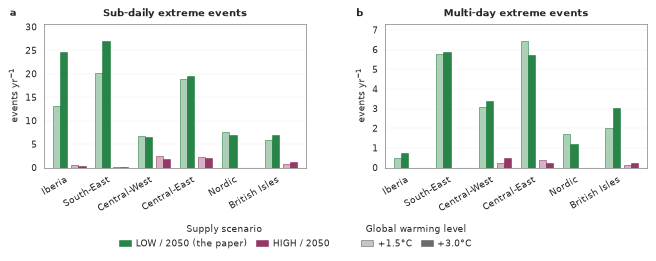

In [31]:
def figure6():
    """One row, one subject: the two duration classes, LOW against HIGH.

    The annual positive residual load used to open this figure and no longer does. It is a LEVEL,
    and a level is Figure 3's subject — this figure is about extremes across timescales, which is
    what its two remaining panels say and nothing else. Nothing went with it: the per-zone levels
    are printed below, and the damping ratios and capacity comparison are in the caption.
    """
    # The SAME row height as Figure 7 and as the top row of Figure 6 and Supplementary Fig. S31, so the four figures
    # read at one scale. Measured rather than assumed: `fit_width` scales the canvas until the
    # rendered WIDTH is 180 mm, so this figsize sets the aspect, and the fixed text margins (rotated
    # zone labels, two legend rows) do not scale with it. At PANEL_ROW_MM these panels come out
    # 41.0 mm against Figure 7's 40.7 and Figure 6 and Supplementary Fig. S31's 41.6 and 40.0. `save` prints it.
    fig, axes = plt.subplots(1, 2, figsize=(WIDTH, PANEL_ROW_MM * MM),
                             gridspec_kw={"wspace": 0.30})
    # Separate y-scales: sub-daily runs to 27 events/yr and multi-day to 6, and a shared axis
    # flattens the multi-day panel to a line on the floor — which is exactly the comparison that
    # decides whether deployment substitutes for storage duration.
    for ax, duration_class in zip(axes, DURATION_BINS):
        panel_scenario_bars(ax, EVENTS_BY_SCENARIO, STYLE, duration_class=duration_class,
                            ylabel="events yr$^{-1}$")
    for letter, ax in zip("ab", axes):
        ax.set_title(SCENARIO_TITLES[letter], fontsize=FS["title"], fontweight="bold")

    fit_width(fig)
    # Both keys apply to both panels, so they sit side by side in ONE row centred under the pair,
    # at one height -- two separate legends under a and under b read as each panel's own key.
    scenario_handles, scenario_labels = axes[0].get_legend_handles_labels()
    fig.canvas.draw()
    _renderer = fig.canvas.get_renderer()
    _floor = min(ax.get_tightbbox(_renderer).y0 for ax in axes) / fig.bbox.height
    _y = _floor - 4.0 / 72 / fig.get_figheight()
    _left, _right = axes[0].get_position().x0, axes[1].get_position().x1
    _mid = 0.5 * (_left + _right)
    fig.legend(scenario_handles, scenario_labels, loc="upper right", ncol=2, frameon=False,
               bbox_to_anchor=(_mid - 0.01, _y), title="Supply scenario")
    fig.legend(*level_handles(STYLE), loc="upper left", ncol=2, frameon=False,
               bbox_to_anchor=(_mid + 0.01, _y), title=GWL_TITLE)
    panel_letters(fig, list(zip("ab", axes)))
    return fig


with publication_rc():
    fig = figure6()
    save(fig, "fig8", FIGS)
plt.show()

# ── The numbers the figure draws, and everything its artwork no longer carries ──────────
# No agreement counts and no spread on the panels themselves, so they are printed here and stated
# in the caption. The damping ratio is HIGH's warming increment over LOW's, paired inside each
# chain: differencing medians instead invents an amplification in Central-West that is not there.
def paired_increment(table, zone, value_column, duration_class=None):
    data = table if duration_class is None else table[table.duration_class == duration_class]
    levels = {p: data[(data.zone == zone) & (data.period == p)].set_index("model")[value_column]
              for p in (REFERENCE, WARMEST)}
    shared = levels[REFERENCE].index.intersection(levels[WARMEST].index)
    change = levels[WARMEST].loc[shared] - levels[REFERENCE].loc[shared]
    median = float(change.median())
    # The sign comparison, unconditionally. Where the median is exactly zero this counts the chains
    # that ALSO show no change, which is the honest reading: a zero median can mean every chain is
    # unchanged (Iberia, South-East and the Nordic multi-day under HIGH, 9/9) or that the chains
    # disagree either side of it (Central-East sub-daily under HIGH, 1/9). Returning len(shared)
    # for both reported the second as the strongest cell in the panel.
    agree = int((np.sign(change) == np.sign(median)).sum())
    return median, agree, float(levels[REFERENCE].loc[shared].median()), \
        float(levels[WARMEST].loc[shared].median())


# The numbers themselves are printed in the next cell. Here only the claim that must HOLD — and
# it is about the residual-load LEVEL, which this figure deliberately no longer draws.
DAMPING = {}
for _zone in zones:
    _low = paired_increment(RESIDUAL_BY_SCENARIO["LOW / 2050 (the paper)"], _zone,
                            "share_of_demand_pct")[0]
    _high = paired_increment(RESIDUAL_BY_SCENARIO["HIGH / 2050"], _zone, "share_of_demand_pct")[0]
    DAMPING[_zone] = _high / _low if abs(_low) > 1e-9 else np.nan

# The build-out damps the warming response in every zone: nothing else in this figure is true in
# all six, so it is the one claim asserted rather than merely printed.
assert all(0.0 <= DAMPING[_z] < 1.0 for _z in zones), \
    f"HIGH no longer damps the warming increment everywhere: {DAMPING}"
print(f"\n|HIGH increment| < |LOW increment| in all six zones, median ratio "
      f"{np.median([DAMPING[_z] for _z in zones]):.2f}")


In [32]:
# ── Numbers behind Figure 8 · every number it draws, plus what its artwork omits ────────
# The panels carry no agreement counts and no spread, so the counts live here and in the caption.
# `n/9` is the number of chains whose own +1.5 -> +3.0 change carries the sign of the median of
# those changes; where that median is exactly zero it counts the chains that are themselves
# unchanged, which separates "every chain agrees there is nothing" (9/9) from "the chains fall
# either side of zero" (1/9). Reporting both as 9/9, as an earlier version did, made the weakest
# cell in the figure look like the strongest.
def scenario_rows(table, value_column, duration_class=None, digits=2):
    rows = {}
    for zone in zones:
        entry = {}
        increments = {}
        for label, data in table.items():
            median, agree, low, high = paired_increment(data, zone, value_column, duration_class)
            short = "LOW" if label.startswith("LOW") else "HIGH"
            # Formatted here rather than by `.round()`: the n/9 column makes the frame object-dtype,
            # so a later round() silently does nothing and the decimals come out ragged.
            entry[(short, REFERENCE)] = f"{low:.{digits}f}"
            entry[(short, WARMEST)] = f"{high:.{digits}f}"
            entry[(short, "Δ")] = f"{median:+.{digits}f}"
            entry[(short, "n/9")] = f"{agree}/{len(models)}"
            increments[short] = median
        if value_column == "share_of_demand_pct":
            entry[("", "damping")] = (f"×{increments['HIGH'] / increments['LOW']:.2f}"
                                      if abs(increments["LOW"]) > 1e-9 else "n/a")
        rows[ZONE_LABELS[zone]] = entry
    frame = pd.DataFrame(rows).T
    frame.columns = pd.MultiIndex.from_tuples(frame.columns)
    return frame


table_figure5_level = scenario_rows(RESIDUAL_BY_SCENARIO, "share_of_demand_pct")
table_figure5_events = {dc: scenario_rows(EVENTS_BY_SCENARIO, "freq_per_year", dc)
                        for dc in DURATION_BINS}

print("Numbers behind Figure 8 · annual POSITIVE residual load as a per cent of the zone's own annual")
print("demand. Positive hours only: under HIGH every zone is a net annual exporter over the year")
print("and still has extreme-event hours. NOT a panel of Figure 8 — the figure is about event")
print("counts across timescales and a level belongs to Figure 3 — but the caption quotes these")
print("numbers, so they are stated here. Δ is the paired increment in percentage points;")
print("`damping` is HIGH's increment over LOW's.\n")
print(table_figure5_level.to_string())

for _class, _panel in zip(DURATION_BINS, "bc"):
    _figure_panel = "a" if _class == "sub_daily" else "b"
    print(f"\nNumbers behind Figure 8{_figure_panel} — {CLASS_LABELS[_class]} extreme events "
          f"per year. Δ is the paired change in events per year.\n")
    print(table_figure5_events[_class].to_string())

_europe = {build: sum(float(v) for v in table_figure5_events["sub_daily"][(build, WARMEST)])
           for build in ("LOW", "HIGH")}
print(f"\nEurope-wide sub-daily total at {WARMEST}: {_europe['LOW']:.1f} events per year under LOW "
      f"against {_europe['HIGH']:.1f} under HIGH "
      f"({100 * (1 - _europe['HIGH'] / _europe['LOW']):.0f} % fewer)")


Numbers behind Figure 8 · annual POSITIVE residual load as a per cent of the zone's own annual
demand. Positive hours only: under HIGH every zone is a net annual exporter over the year
and still has extreme-event hours. NOT a panel of Figure 8 — the figure is about event
counts across timescales and a level belongs to Figure 3 — but the caption quotes these
numbers, so they are stated here. Δ is the paired increment in percentage points;
`damping` is HIGH's increment over LOW's.

                 LOW                      HIGH                           
              +1.5°C +3.0°C      Δ  n/9 +1.5°C +3.0°C      Δ  n/9 damping
Iberia         16.21  18.22  +1.43  9/9   3.91   5.14  +0.94  9/9   ×0.66
South-East     33.52  33.86  +0.49  8/9   4.11   4.37  +0.21  9/9   ×0.42
Central-West    9.37   9.64  +0.26  6/9   3.39   3.73  +0.13  5/9   ×0.49
Central-East   47.03  46.65  -0.17  7/9  10.42  10.03  -0.02  5/9   ×0.13
Nordic          2.31   2.31  -0.14  7/9   0.01   0.01  -0.00  5/9   ×0.

## 9 · Verification

In [34]:
# ── The invariants the figures rest on ──────────────────────────────────────────────────
checks = {}

# 1. The storage stacked bar is an identity, not an approximation.
sa = storage_attenuation.dropna(subset=["combined_attenuation_pct"])
residual = (sa["reservoir_attenuation_share_pct"] + sa["battery_attenuation_share_pct"]
            - sa["combined_attenuation_pct"]).abs()
checks["storage shares sum to combined (max |residual|)"] = float(residual.max())
assert residual.max() < 1e-6, "the stacked storage bar does not close"

# 2. Figures 2 and 3's simplified geometry covers the same countries as the full geometry, and in
#    particular has not dropped the small ones.
for iso in ("LU", "MT", "CY", "SI", "ME"):
    if iso in set(countries["ISO2"]):
        assert iso in set(countries_print["ISO2"]), f"{iso} lost to simplification"
checks["countries kept after simplify(0.02)"] = len(countries_print)

# 3. Every rendered file is within the artwork rules. `save` asserts width and type size on the
#    way out, so reaching this point means all six passed; record the file sizes.
written = sorted(FIGS.glob("fig*.pdf"))
checks["figures written (pdf)"] = len(written)
assert len(written) == 7, f"expected 7 PDFs (Figures 2-8; 1 is external), found {[p.name for p in written]}"
assert [p.stem for p in written] == [f"fig{i}" for i in range(2, 9)], \
    f"the figure numbering has a gap or a duplicate: {[p.name for p in written]}"

# 3b. The contribution panel of Figure 6b and Supplementary Fig. S31b. Because the four seasonal counts sum to the
#     annual count EXACTLY (compute_event_season_metrics assigns each event whole to one season), a
#     CHAIN's four contributions must sum to that chain's own annual per-cent change exactly. The
#     four MEDIANS need not, and do not, because the median of a sum is not the sum of medians, so
#     assert the per-chain identity and merely BOUND the median row sum. The bound is why the
#     caption must not invite a reader to add a row.
worst_chain, worst_median = 0.0, []
for duration_class in DURATION_BINS:
    for zone in zones:
        per_chain = [season_contribution_by_model(events_by_season, events_annual, zone, season,
                                                  duration_class, STYLE)[0]
                     for season in SEASON_ORDER]
        annual = {p: events_annual[(events_annual.zone == zone)
                                   & (events_annual.duration_class == duration_class)
                                   & (events_annual.period == p)].set_index("model")["freq_per_year"]
                  for p in (REFERENCE, WARMEST)}
        chains = (set.intersection(*(set(s.index) for s in per_chain))
                  if all(len(s) for s in per_chain) else set())
        for chain in chains:
            reference = annual[REFERENCE].get(chain, 0.0)
            if reference <= 0:
                continue
            expected = 100 * (annual[WARMEST][chain] - reference) / reference
            worst_chain = max(worst_chain, abs(sum(s[chain] for s in per_chain) - expected))
        if not chains:
            continue
        total = sum(float(s.median()) for s in per_chain if len(s))
        reference, warmest = annual[REFERENCE], annual[WARMEST]
        usable = reference > 0
        paired = float((100 * (warmest[usable] - reference[usable]) / reference[usable]).median())
        worst_median.append((abs(total - paired), f"{ZONE_LABELS[zone]} {duration_class}: "
                             f"rows sum to {total:+.1f} against {paired:+.1f} annual"))
checks["max |a chain's 4 contributions - its annual % change|"] = round(worst_chain, 9)
assert worst_chain < 1e-6, "a chain's contributions do not close; the panel b quantity is wrong"
worst_median.sort(reverse=True)
checks["worst median row sum against the annual median"] = worst_median[0][1]
assert worst_median[0][0] <= 25.0, f"median rows drifted past 25 points: {worst_median[:3]}"

# 3c. Figure 5b's hours must be the counts of Figure 6a and Supplementary Fig. S31a times the mean event duration, which
#     is what ties the burden panel to the frequency panels rather than leaving them unrelated.
_probe = events_by_season.dropna(subset=["avg_duration_h"])
_probe = _probe[_probe["freq_per_year"] > 0]
checks["max |hours - freq x duration|"] = float(
    (_probe["hours_yr"] - _probe["freq_per_year"] * _probe["avg_duration_h"]).abs().max())
assert checks["max |hours - freq x duration|"] < 1e-9, "the burden table is not counts x duration"

# 4. Fonts actually embedded, and actually the family we asked for.
import subprocess
for path in written:
    try:
        out = subprocess.run(["pdffonts", str(path)], capture_output=True, text=True, timeout=30)
        if out.returncode == 0:
            families = {line.split()[0].split("+")[-1] for line in out.stdout.splitlines()[2:]
                        if line.strip()}
            types = {line.split()[1] for line in out.stdout.splitlines()[2:] if line.strip()}
            print(f"  {path.name:<38} {sorted(families)}  {sorted(types)}")
    except (FileNotFoundError, subprocess.TimeoutExpired):
        print("  pdffonts unavailable \u2014 font embedding not verified here")
        break


# 7. THE ANNOTATION AND THE GEOMETRY MUST NOT DISAGREE IN SIGN. Figure 7b previously annotated a
#    -8 % change over boxes whose medians were flat: the paired median of nine per-chain changes
#    running -33 to +45 % is a property of the median, not of the ensemble, and the unpaired
#    difference of the drawn medians was +0.7 %. A reader compares a label with the picture beside
#    it, so any panel whose printed statistic disagrees in sign with the medians it is drawn over is
#    reporting two different things at once. Paired and unpaired legitimately differ, so this is a
#    FLAG rather than an automatic failure — but nothing may ship unexamined.
def annotation_sign_conflicts(table, value_column, categories, category_column,
                              *, duration_class=None, floor=1e-9, material_pct=2.0):
    """(category, paired %, unpaired %) wherever the two disagree in sign.

    ``material_pct`` applies to the LARGER of the two, not the smaller. Requiring both to clear it
    would suppress the very shape this check is for -- a sizeable paired change against a near-zero
    unpaired one, which is Figure 7b's withdrawn multi-day label at -8.4 % against +0.7 %.
    """
    data = (table if duration_class is None
            else table[table.duration_class == duration_class])
    conflicts = []
    for category in categories:
        rows = data[data[category_column] == category]
        ref = rows[rows.period == REFERENCE].set_index("model")[value_column]
        warm = rows[rows.period == WARMEST].set_index("model")[value_column]
        shared = ref.index.intersection(warm.index)
        if not len(shared) or not np.isfinite(ref.loc[shared]).any():
            continue
        paired = float(((warm.loc[shared] - ref.loc[shared]) / ref.loc[shared] * 100).median())
        drawn_lo, drawn_hi = float(ref.loc[shared].median()), float(warm.loc[shared].median())
        unpaired = (drawn_hi - drawn_lo) / drawn_lo * 100 if abs(drawn_lo) > floor else np.nan
        if np.isfinite(unpaired) and np.sign(paired) != np.sign(unpaired) \
                and max(abs(paired), abs(unpaired)) > material_pct:
            conflicts.append((category, round(paired, 1), round(unpaired, 1)))
    return conflicts

#    Known conflicts are PINNED rather than forbidden. Paired and unpaired legitimately differ, and
#    one cell has differed since the paired estimator was adopted: Central-West's sub-daily count
#    goes 6.75 -> 6.55 per year as a ratio of medians (-3 %) while seven of nine chains rise, which
#    is the +7 % Figure 6a prints. That one is examined, documented in the panel-title cell, and
#    accepted. Anything NOT on this list is new and fails.
KNOWN_ANNOTATION_CONFLICTS = {
    # panel, why it is accepted
    "fig6a sub_daily Central_Western":
        "the median chain differs between levels; 7/9 chains rise while the ratio of medians falls",
}

_annotated = {}
# Figure 6a and Supplementary Fig. S31a annotate the paired change per zone; Figure 7b annotates a composition instead,
# so it is checked on the statistic it WOULD have annotated, which is what must stay retired.
# Both duration classes are still checked even though only the sub-daily one is a main figure:
# the multi-day panel is Supplementary Fig. S31, drawn by the SAME builder from the SAME table, so
# a conflict there is a conflict here.
for _class, _letter in zip(DURATION_BINS, ("fig6a", "S31a")):
    for _category, _paired, _unpaired in annotation_sign_conflicts(
            events_annual, "freq_per_year", zones, "zone", duration_class=_class):
        _annotated[f"{_letter} {_class} {_category}"] = (_paired, _unpaired)
checks["annotation/geometry sign conflicts"] = _annotated
_new = set(_annotated) - set(KNOWN_ANNOTATION_CONFLICTS)
_gone = set(KNOWN_ANNOTATION_CONFLICTS) - set(_annotated)
assert not _new, (
    "a panel annotates a change whose sign contradicts the medians it is drawn over, and it is not "
    f"one of the examined cases: {{k: _annotated[k] for k in _new}}. Either retire the label (as "
    "Figure 7b did), restate it, or add it to KNOWN_ANNOTATION_CONFLICTS with a reason.")
assert not _gone, (
    f"{sorted(_gone)} no longer conflicts; drop it from KNOWN_ANNOTATION_CONFLICTS so the list "
    "keeps meaning 'examined and accepted' rather than 'stale'.")
# The Europe-severity total this used to guard is gone: Figure 7b is now absolute energy by
# duration, which carries no change annotation at all and so cannot contradict its own geometry.
print("annotation signs: "
      + (f"{len(_annotated)} examined conflict(s), all pinned" if _annotated else "no conflicts"))

for name, value in checks.items():
    print(f"  {name:<48} {value}")
print("\nAll figure assertions passed.")

  fig2.pdf                               ['DejaVuSans', 'DejaVuSans-Bold']  ['CID']
  fig3.pdf                               ['DejaVuSans', 'DejaVuSans-Bold']  ['CID']
  fig4.pdf                               ['DejaVuSans', 'DejaVuSans-Bold']  ['CID']
  fig5.pdf                               ['DejaVuSans', 'DejaVuSans-Bold']  ['CID']
  fig6.pdf                               ['DejaVuSans', 'DejaVuSans-Bold']  ['CID']
  fig7.pdf                               ['DejaVuSans', 'DejaVuSans-Bold']  ['CID']
  fig8.pdf                               ['DejaVuSans', 'DejaVuSans-Bold']  ['CID']
annotation signs: 1 examined conflict(s), all pinned
  storage shares sum to combined (max |residual|)  4.263256414560601e-14
  countries kept after simplify(0.02)              61
  figures written (pdf)                            7
  max |a chain's 4 contributions - its annual % change| 0.0
  worst median row sum against the annual median   Iberia multi_day: rows sum to +64.8 against +50.0 annual
  max |hour